In [1]:
import warnings # 导入必要的库
warnings.filterwarnings('ignore') # 忽略警告信息，避免输出干扰
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno#missingno专为缺失值可视化设计，可直观展示缺失模式。

原理说明
库选择依据：pandas用于数据结构化处理（如读取、筛选、统计）；numpy支持高效数值计算；matplotlib和seaborn用于数据可视化，其中seaborn基于matplotlib提供更美观的统计图表；missingno专为缺失值可视化设计，可直观展示缺失模式。
数据读取：使用pd.read_csv读取 CSV 文件，sep=' '指定分隔符为空格（因数据集采用空格分隔）。训练集包含目标变量price（二手车价格），测试集用于最终预测，二者结构相似但测试集少price列。

In [44]:
import os
import pandas as pd

train_data=pd.read_csv(r'G:\第三周\data\used_car_train_20200313\used_car_train_20200313.csv',sep=' ')
test_data=pd.read_csv(r'G:\第三周\data\used_car_testA_20200313\used_car_testA_20200313.csv',sep=' ')

In [45]:
print(type(train_data))

<class 'pandas.core.frame.DataFrame'>


In [46]:
train_data.head().append(train_data.tail())

,SaleID,name,regDate,model,brand,bodyType,fuelType,gearbox,power,kilometer,...,v_5,v_6,v_7,v_8,v_9,v_10,v_11,v_12,v_13,v_14
0,0,736,20040402,30.0,6,1.0,0.0,0.0,60,12.5,...,0.235676,0.101988,0.129549,0.022816,0.097462,-2.881803,2.804097,-2.420821,0.795292,0.914762
1,1,2262,20030301,40.0,1,2.0,0.0,0.0,0,15.0,...,0.264777,0.121004,0.135731,0.026597,0.020582,-4.900482,2.096338,-1.030483,-1.722674,0.245522
2,2,14874,20040403,115.0,15,1.0,0.0,0.0,163,12.5,...,0.251410,0.114912,0.165147,0.062173,0.027075,-4.846749,1.803559,1.565330,-0.832687,-0.229963
3,3,71865,19960908,109.0,10,0.0,0.0,1.0,193,15.0,...,0.274293,0.110300,0.121964,0.033395,0.000000,-4.509599,1.285940,-0.501868,-2.438353,-0.478699
4,4,111080,20120103,110.0,5,1.0,0.0,0.0,68,5.0,...,0.228036,0.073205,0.091880,0.078819,0.121534,-1.896240,0.910783,0.931110,2.834518,1.923482
149995,149995,163978,20000607,121.0,10,4.0,0.0,1.0,163,15.0,...,0.280264,0.000310,0.048441,0.071158,0.019174,1.988114,-2.983973,0.589167,-1.304370,-0.302592
149996,149996,184535,20091102,116.0,11,0.0,0.0,0.0,125,10.0,...,0.253217,0.000777,0.084079,0.099681,0.079371,1.839166,-2.774615,2.553994,0.924196,-0.272160
149997,149997,147587,20101003,60.0,11,1.0,1.0,0.0,90,6.0,...,0.233353,0.000705,0.118872,0.100118,0.097914,2.439812,-1.630677,2.290197,1.891922,0.414931
149998,149998,45907,20060312,34.0,10,3.0,1.0,0.0,156,15.0,...,0.256369,0.000252,0.081479,0.083558,0.081498,2.075380,-2.633719,1.414937,0.431981,-1.659014
149999,149999,177672,19990204,19.0,28,6.0,0.0,1.0,193,12.5,...,0.284475,0.000000,0.040072,0.062543,0.025819,1.978453,-3.179913,0.031724,-1.483350,-0.342674


In [47]:
train_data.shape

(150000, 31)

In [48]:
test_data.shape

(50000, 30)

In [49]:
train_data.describe()

,SaleID,name,regDate,model,brand,bodyType,fuelType,gearbox,power,kilometer,...,v_5,v_6,v_7,v_8,v_9,v_10,v_11,v_12,v_13,v_14
count,150000.000000,150000.000000,1.500000e+05,149999.000000,150000.000000,145494.000000,141320.000000,144019.000000,150000.000000,150000.000000,...,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,74999.500000,68349.172873,2.003417e+07,47.129021,8.052733,1.792369,0.375842,0.224943,119.316547,12.597160,...,0.248204,0.044923,0.124692,0.058144,0.061996,-0.001000,0.009035,0.004813,0.000313,-0.000688
std,43301.414527,61103.875095,5.364988e+04,49.536040,7.864956,1.760640,0.548677,0.417546,177.168419,3.919576,...,0.045804,0.051743,0.201410,0.029186,0.035692,3.772386,3.286071,2.517478,1.288988,1.038685
min,0.000000,0.000000,1.991000e+07,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,...,0.000000,0.000000,0.000000,0.000000,0.000000,-9.168192,-5.558207,-9.639552,-4.153899,-6.546556
25%,37499.750000,11156.000000,1.999091e+07,10.000000,1.000000,0.000000,0.000000,0.000000,75.000000,12.500000,...,0.243615,0.000038,0.062474,0.035334,0.033930,-3.722303,-1.951543,-1.871846,-1.057789,-0.437034
50%,74999.500000,51638.000000,2.003091e+07,30.000000,6.000000,1.000000,0.000000,0.000000,110.000000,15.000000,...,0.257798,0.000812,0.095866,0.057014,0.058484,1.624076,-0.358053,-0.130753,-0.036245,0.141246
75%,112499.250000,118841.250000,2.007111e+07,66.000000,13.000000,3.000000,1.000000,0.000000,150.000000,15.000000,...,0.265297,0.102009,0.125243,0.079382,0.087491,2.844357,1.255022,1.776933,0.942813,0.680378
max,149999.000000,196812.000000,2.015121e+07,247.000000,39.000000,7.000000,6.000000,1.000000,19312.000000,15.000000,...,0.291838,0.151420,1.404936,0.160791,0.222787,12.357011,18.819042,13.847792,11.147669,8.658418


In [50]:
test_data.describe()

,SaleID,name,regDate,model,brand,bodyType,fuelType,gearbox,power,kilometer,...,v_5,v_6,v_7,v_8,v_9,v_10,v_11,v_12,v_13,v_14
count,50000.000000,50000.000000,5.000000e+04,50000.000000,50000.000000,48587.000000,47107.000000,48090.000000,50000.000000,50000.000000,...,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,174999.500000,68542.223280,2.003393e+07,46.844520,8.056240,1.782185,0.373405,0.224350,119.883620,12.595580,...,0.248669,0.045021,0.122744,0.057997,0.062000,-0.017855,-0.013742,-0.013554,-0.003147,0.001516
std,14433.901067,61052.808133,5.368870e+04,49.469548,7.819477,1.760736,0.546442,0.417158,185.097387,3.908979,...,0.044601,0.051766,0.195972,0.029211,0.035653,3.747985,3.231258,2.515962,1.286597,1.027360
min,150000.000000,0.000000,1.991000e+07,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,...,0.000000,0.000000,0.000000,0.000000,0.000000,-9.160049,-5.411964,-8.916949,-4.123333,-6.112667
25%,162499.750000,11203.500000,1.999091e+07,10.000000,1.000000,0.000000,0.000000,0.000000,75.000000,12.500000,...,0.243762,0.000044,0.062644,0.035084,0.033714,-3.700121,-1.971325,-1.876703,-1.060428,-0.437920
50%,174999.500000,52248.500000,2.003091e+07,29.000000,6.000000,1.000000,0.000000,0.000000,109.000000,15.000000,...,0.257877,0.000815,0.095828,0.057084,0.058764,1.613212,-0.355843,-0.142779,-0.035956,0.138799
75%,187499.250000,118856.500000,2.007110e+07,65.000000,13.000000,3.000000,1.000000,0.000000,150.000000,15.000000,...,0.265328,0.102025,0.125438,0.079077,0.087489,2.832708,1.262914,1.764335,0.941469,0.681163
max,199999.000000,196805.000000,2.015121e+07,246.000000,39.000000,7.000000,6.000000,1.000000,20000.000000,15.000000,...,0.291618,0.153265,1.358813,0.156355,0.214775,12.338872,18.856218,12.950498,5.913273,2.624622


In [51]:
train_data.isnull().sum()# 统计训练集各特征缺失值数量

SaleID                  0
name                    0
regDate                 0
model                   1
brand                   0
bodyType             4506
fuelType             8680
gearbox              5981
power                   0
kilometer               0
notRepairedDamage       0
regionCode              0
seller                  0
offerType               0
creatDate               0
price                   0
v_0                     0
v_1                     0
v_2                     0
v_3                     0
v_4                     0
v_5                     0
v_6                     0
v_7                     0
v_8                     0
v_9                     0
v_10                    0
v_11                    0
v_12                    0
v_13                    0
v_14                    0
dtype: int64

In [52]:
test_data.isnull().sum()# 统计测试集各特征缺失值数量

SaleID                  0
name                    0
regDate                 0
model                   0
brand                   0
bodyType             1413
fuelType             2893
gearbox              1910
power                   0
kilometer               0
notRepairedDamage       0
regionCode              0
seller                  0
offerType               0
creatDate               0
v_0                     0
v_1                     0
v_2                     0
v_3                     0
v_4                     0
v_5                     0
v_6                     0
v_7                     0
v_8                     0
v_9                     0
v_10                    0
v_11                    0
v_12                    0
v_13                    0
v_14                    0
dtype: int64

<AxesSubplot:>

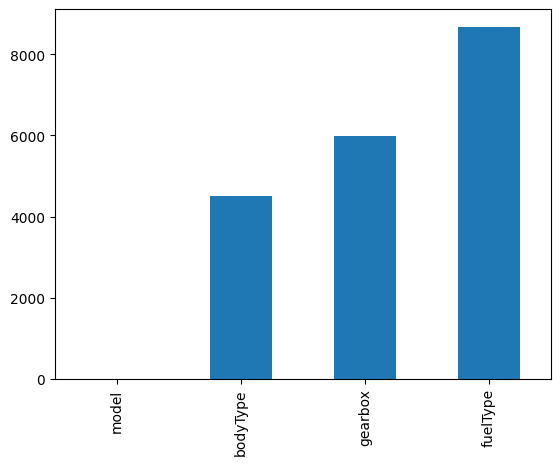

In [55]:
missing = train_data.isnull().sum()# 可视化训练集缺失值分布
missing = missing[missing > 0]# 筛选有缺失的特征并排序
missing.sort_values(inplace=True)
missing.plot.bar()# 缺失值数量条形图

<AxesSubplot:>

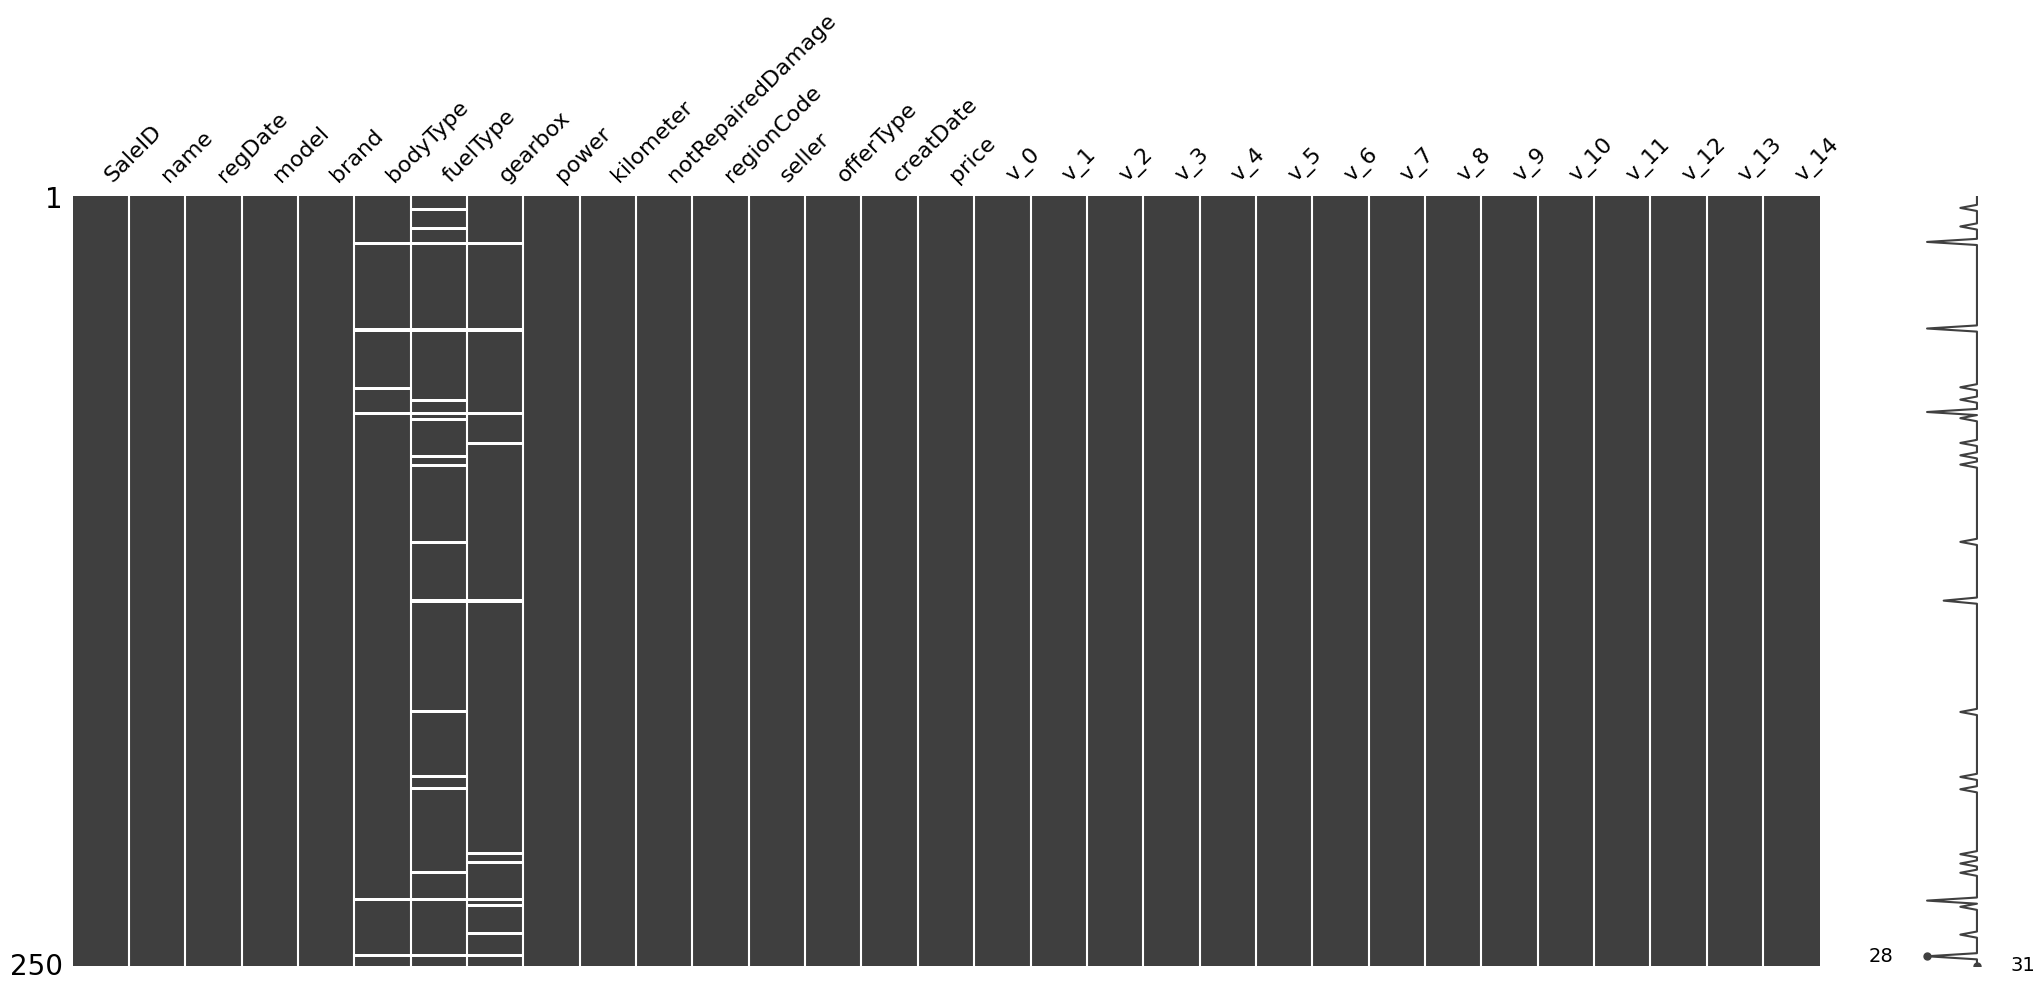

In [57]:
msno.matrix(train_data.sample(250))# 随机抽样250条样本，展示缺失值位置矩阵

<AxesSubplot:>

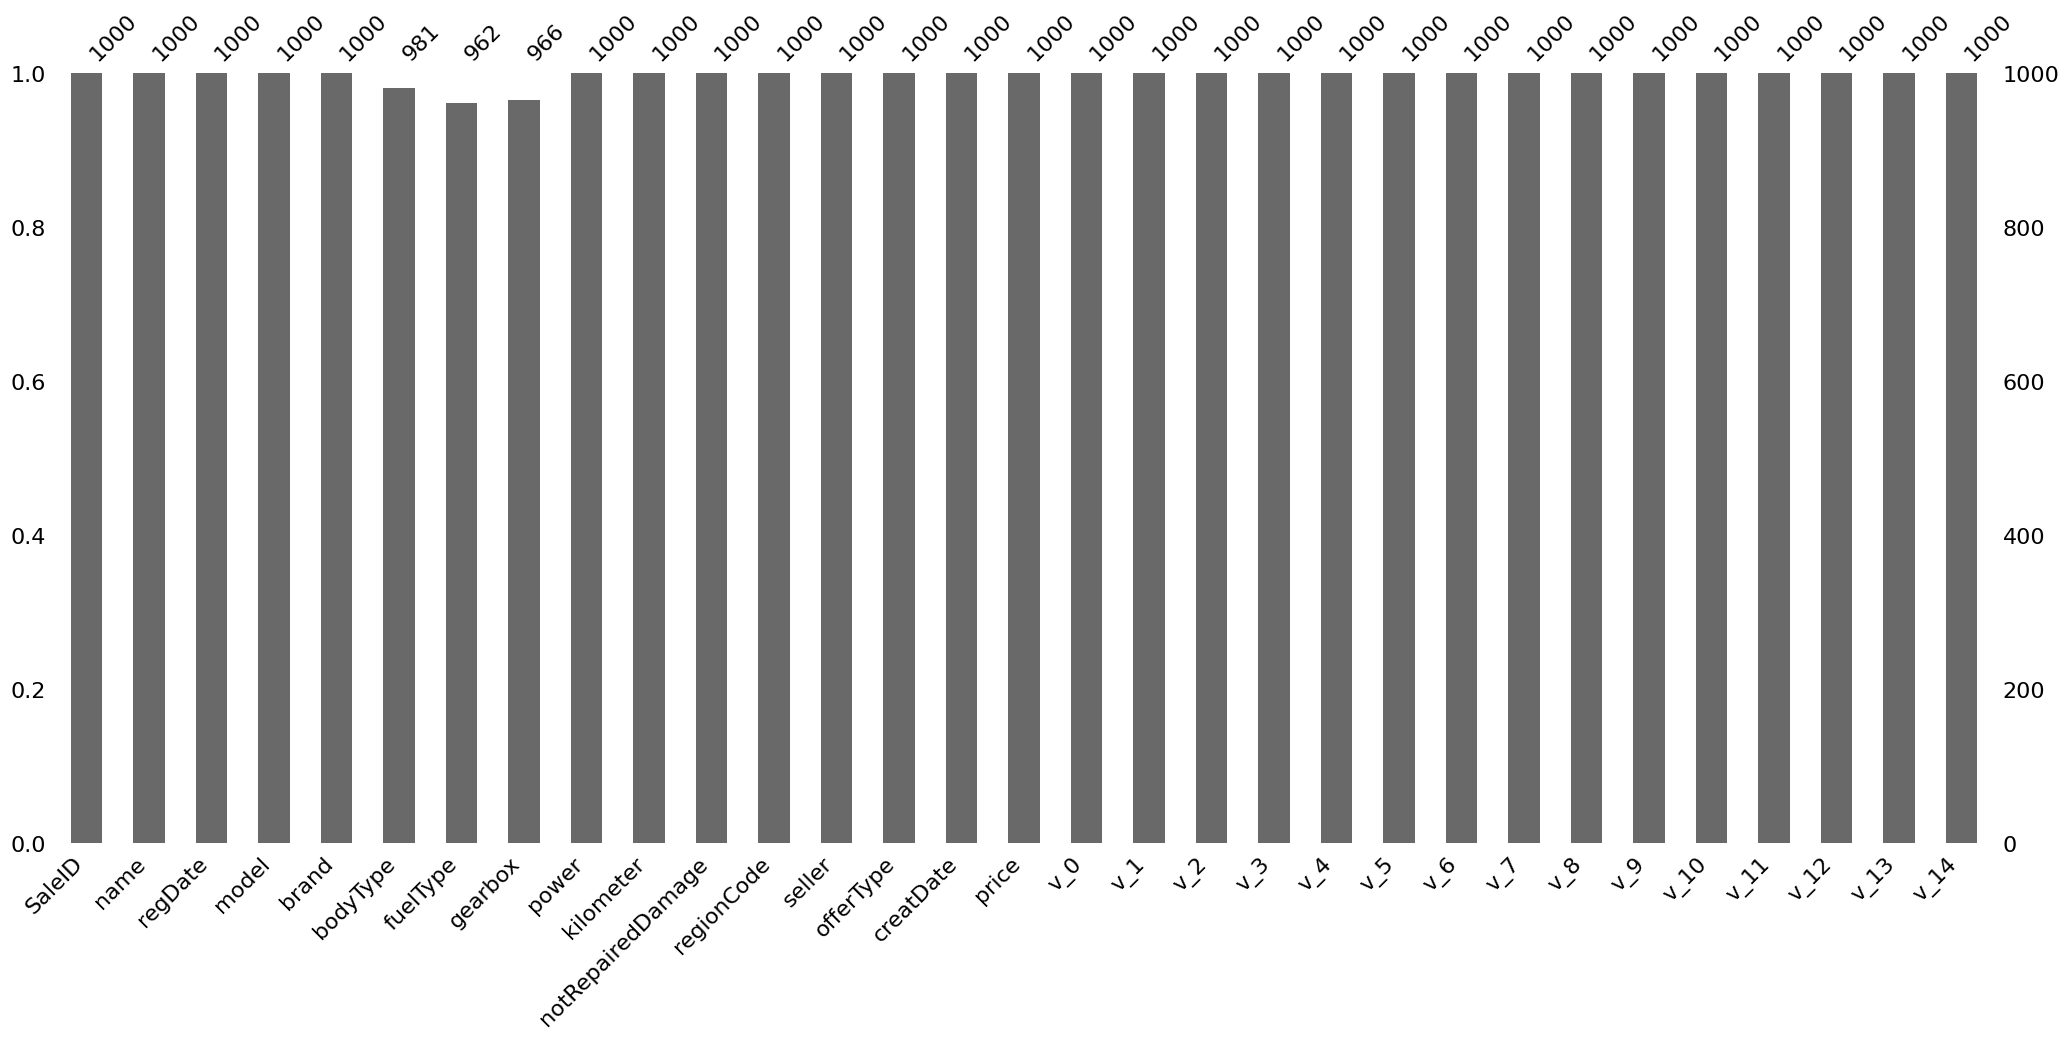

In [60]:
msno.bar(train_data.sample(1000))# 缺失值占比条形图

<AxesSubplot:>

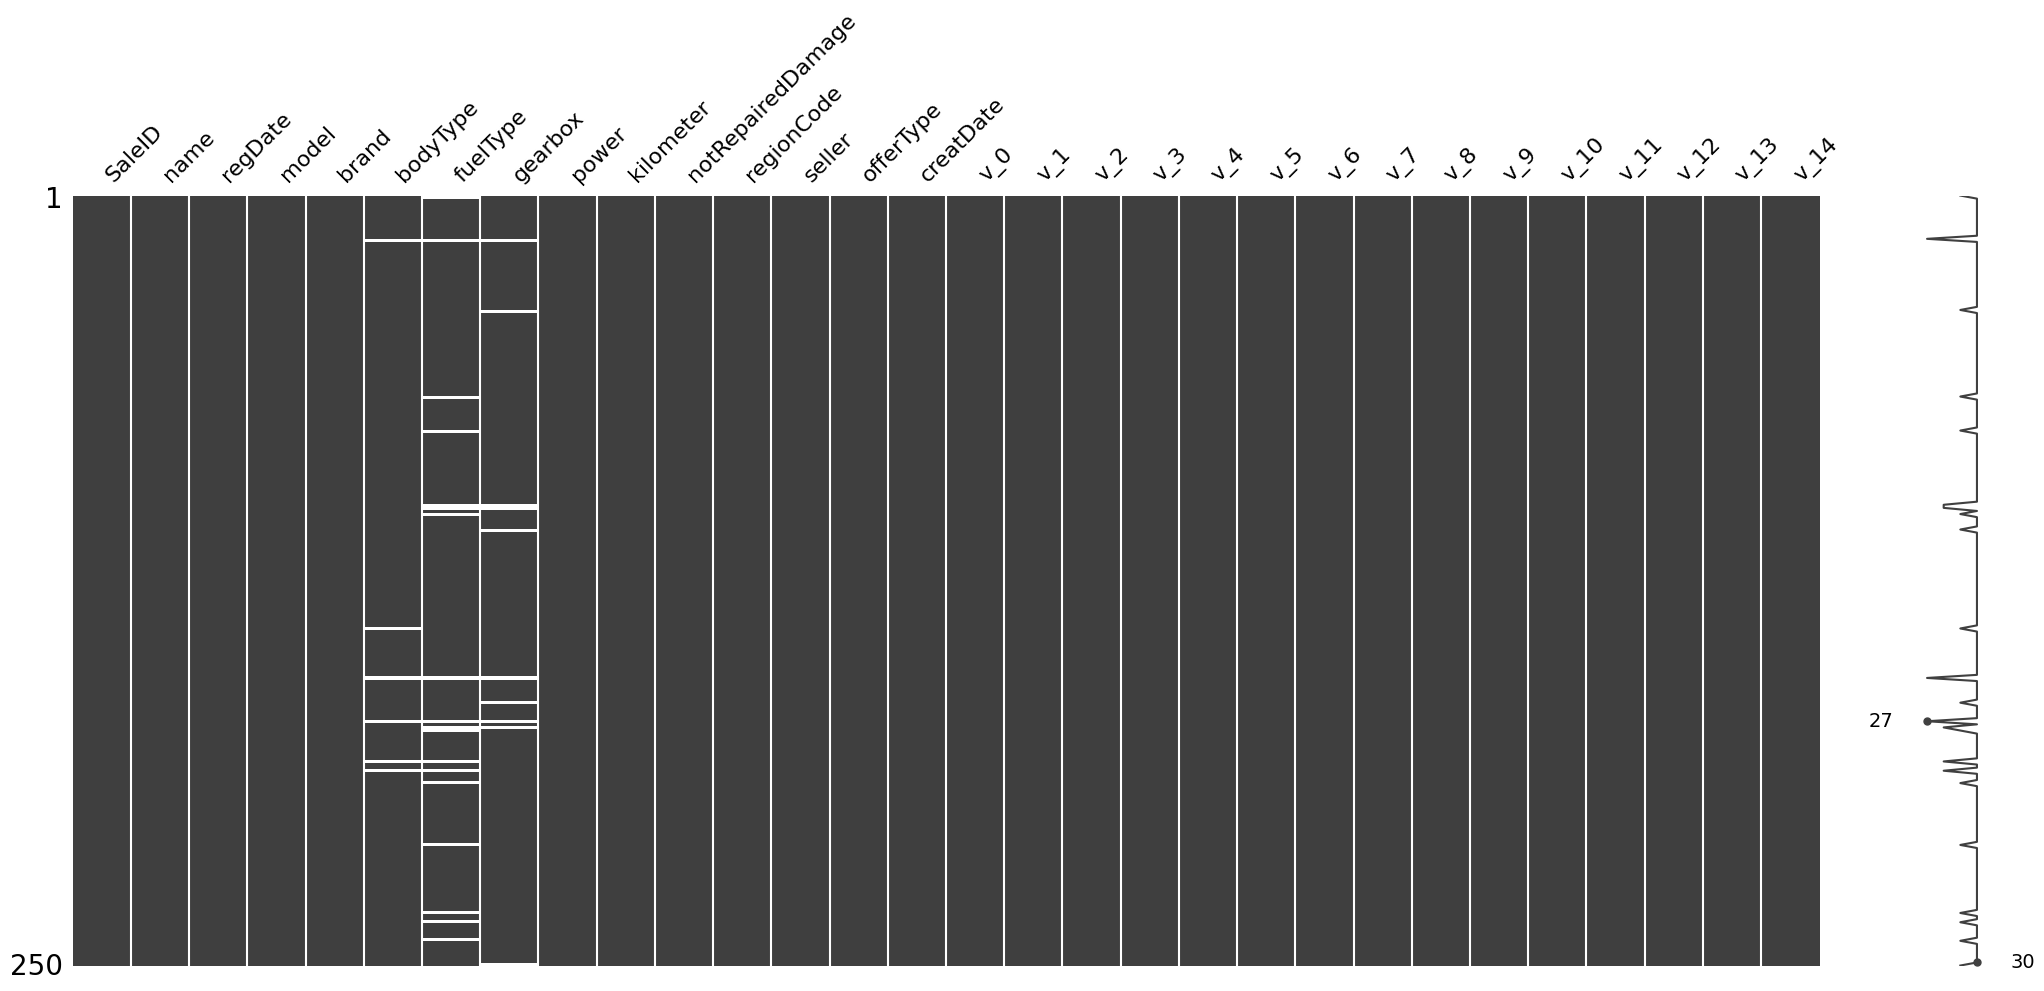

In [61]:
msno.matrix(test_data.sample(250))# 可视化测试集缺失值分布

<AxesSubplot:>

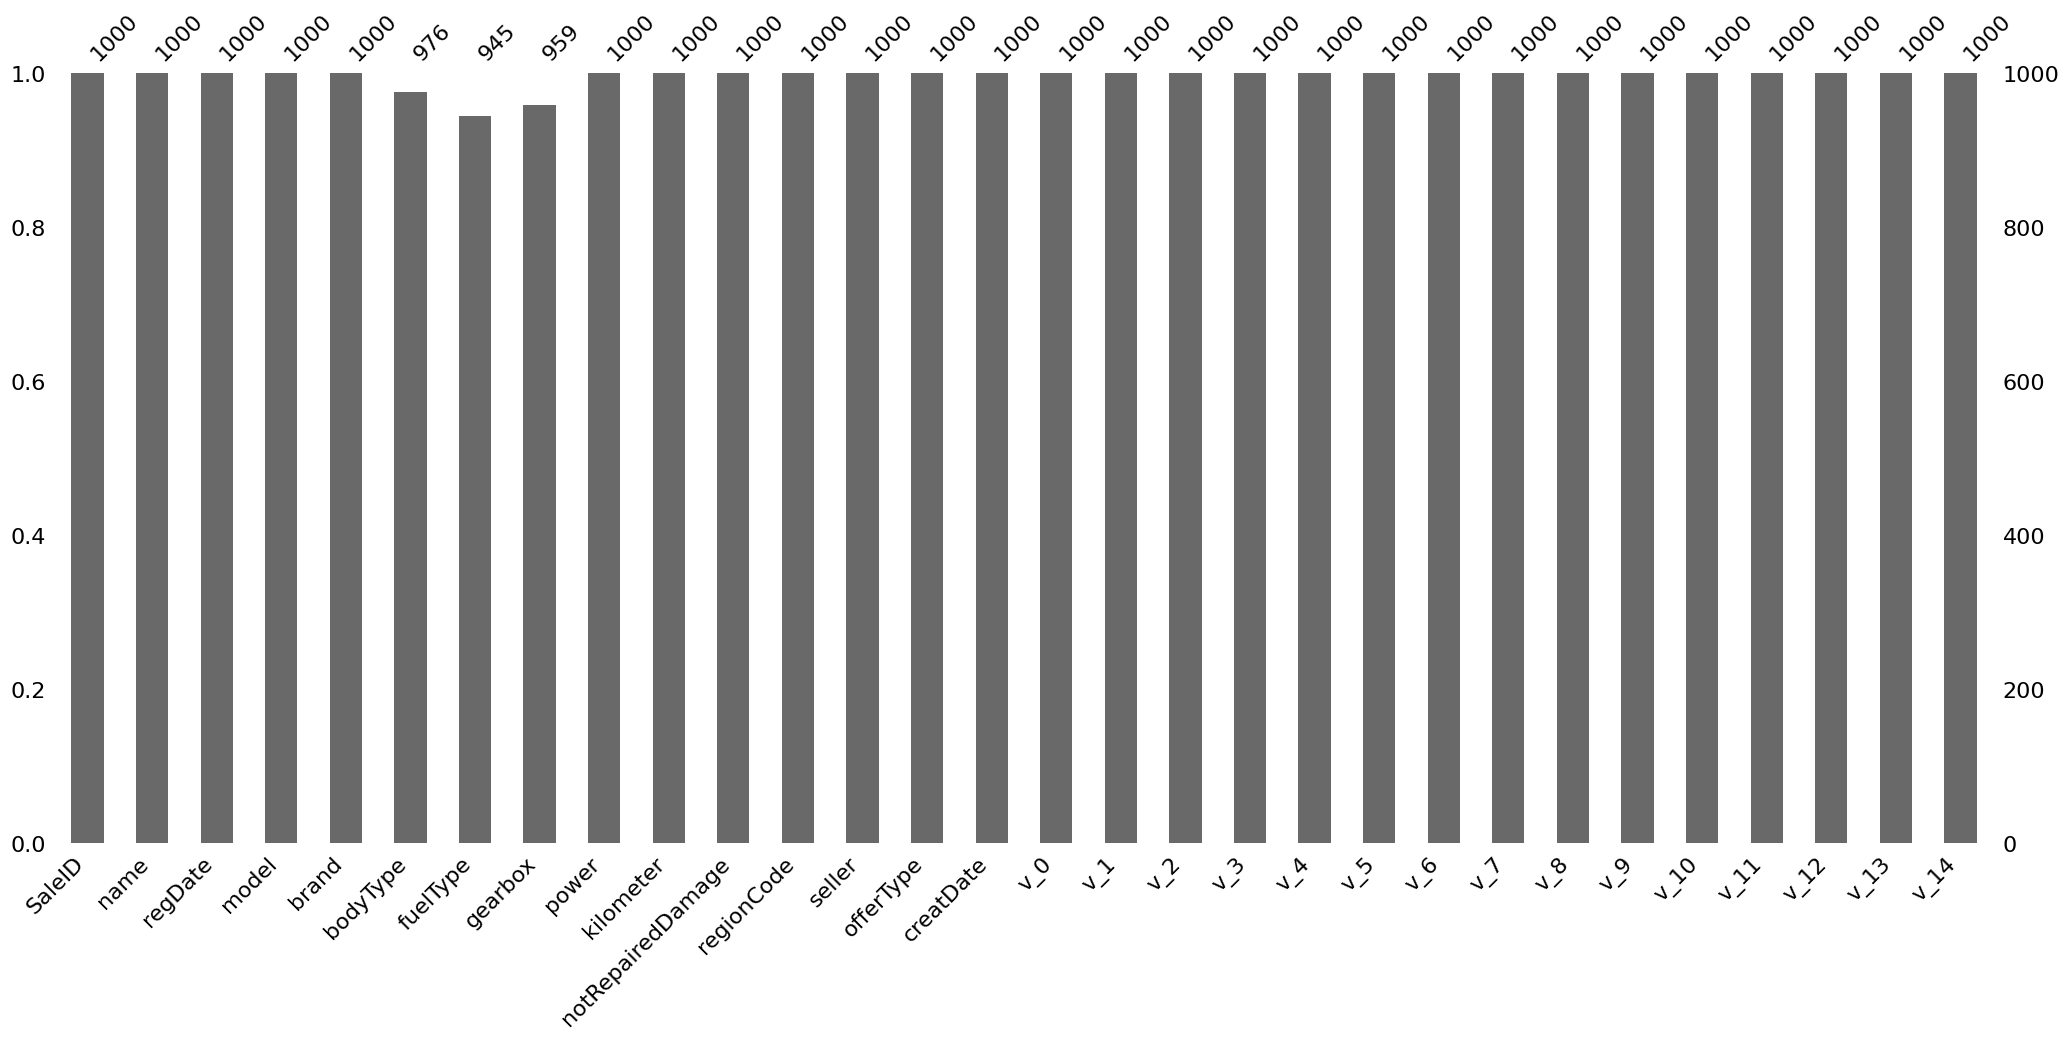

In [62]:
msno.bar(test_data.sample(1000))# 可视化测试集缺失值分布

原理说明
缺失值统计：isnull().sum()计算每个特征的缺失值数量，结果显示训练集中fuelType（8680 个缺失）、gearbox（5981 个）、bodyType（4506 个）缺失较多，model仅 1 个缺失，其余特征无缺失。
缺失值可视化：
msno.matrix：以矩阵形式展示缺失值位置（白色为缺失），可观察缺失是否存在规律（如是否集中在某些样本）。
msno.bar：展示各特征的非缺失值比例，直观判断缺失严重程度（如fuelType非缺失值占比约 94%）。
意义：缺失值过多可能导致特征信息丢失，需在预处理阶段处理（如填充均值 / 中位数、用模型预测缺失值）。

In [64]:
train_data.info()# 查看训练集各特征的数据类型及非空数量

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 31 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   SaleID             150000 non-null  int64  
 1   name               150000 non-null  int64  
 2   regDate            150000 non-null  int64  
 3   model              149999 non-null  float64
 4   brand              150000 non-null  int64  
 5   bodyType           145494 non-null  float64
 6   fuelType           141320 non-null  float64
 7   gearbox            144019 non-null  float64
 8   power              150000 non-null  int64  
 9   kilometer          150000 non-null  float64
 10  notRepairedDamage  150000 non-null  object 
 11  regionCode         150000 non-null  int64  
 12  seller             150000 non-null  int64  
 13  offerType          150000 non-null  int64  
 14  creatDate          150000 non-null  int64  
 15  price              150000 non-null  int64  
 16  v_

In [65]:
train_data['notRepairedDamage'].value_counts()# 查看notRepairedDamage的取值分布（发现异常值'-'）

0.0    111361
-       24324
1.0     14315
Name: notRepairedDamage, dtype: int64

In [66]:
train_data['notRepairedDamage'].replace('-', np.nan, inplace=True)# 将'-'转换为NaN（表示缺失）

In [67]:
train_data['notRepairedDamage'].value_counts()

0.0    111361
1.0     14315
Name: notRepairedDamage, dtype: int64

In [68]:
train_data.isnull().sum()

SaleID                   0
name                     0
regDate                  0
model                    1
brand                    0
bodyType              4506
fuelType              8680
gearbox               5981
power                    0
kilometer                0
notRepairedDamage    24324
regionCode               0
seller                   0
offerType                0
creatDate                0
price                    0
v_0                      0
v_1                      0
v_2                      0
v_3                      0
v_4                      0
v_5                      0
v_6                      0
v_7                      0
v_8                      0
v_9                      0
v_10                     0
v_11                     0
v_12                     0
v_13                     0
v_14                     0
dtype: int64

In [69]:
test_data['notRepairedDamage'].value_counts()

0.0    37249
-       8031
1.0     4720
Name: notRepairedDamage, dtype: int64

In [70]:
test_data['notRepairedDamage'].replace('-', np.nan, inplace=True)

In [71]:
train_data["seller"].value_counts()# 查看seller和offerType的取值分布（取值单一，无预测价值）

0    149999
1         1
Name: seller, dtype: int64

In [72]:
train_data["offerType"].value_counts()

0    150000
Name: offerType, dtype: int64

In [73]:
del train_data["seller"]# 删除无用特征
del train_data["offerType"]
del test_data["seller"]
del test_data["offerType"]

原理说明
数据类型检查：info()显示特征的dtype（如SaleID为int64，notRepairedDamage为object），确保数值特征为int64/float64，分类型特征为object/category，否则需转换（如notRepairedDamage后续转为数值型）。
异常值处理：notRepairedDamage中存在非数值 '-'，不符合特征定义（应为 0/1 表示是否维修），故转为NaN作为缺失值处理。
低信息量特征删除：seller和offerType取值几乎不变（如offerType全为 0），无法为模型提供有效信息，删除可减少计算量。

In [74]:
train_data['price']# 输出各样本价格，长度150000

0         1850
1         3600
2         6222
3         2400
4         5200
          ... 
149995    5900
149996    9500
149997    7500
149998    4999
149999    4700
Name: price, Length: 150000, dtype: int64

In [75]:
train_data['price'].value_counts()# 查看price的取值分布（不同价格的样本数量）

500      2337
1500     2158
1200     1922
1000     1850
2500     1821
         ... 
1433        1
8911        1
12877       1
9885        1
8188        1
Name: price, Length: 3763, dtype: int64

<AxesSubplot:title={'center':'Log Normal'}, xlabel='price'>

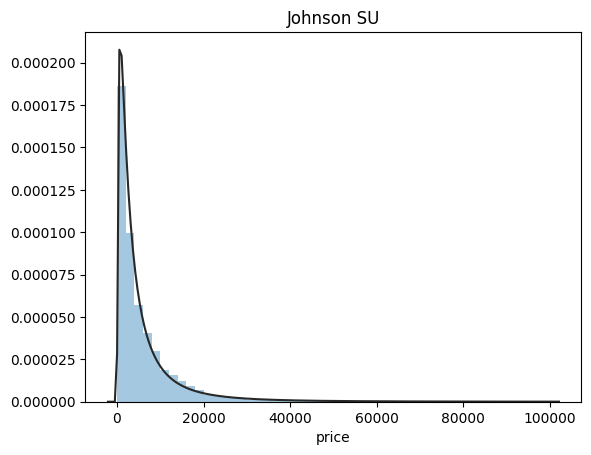

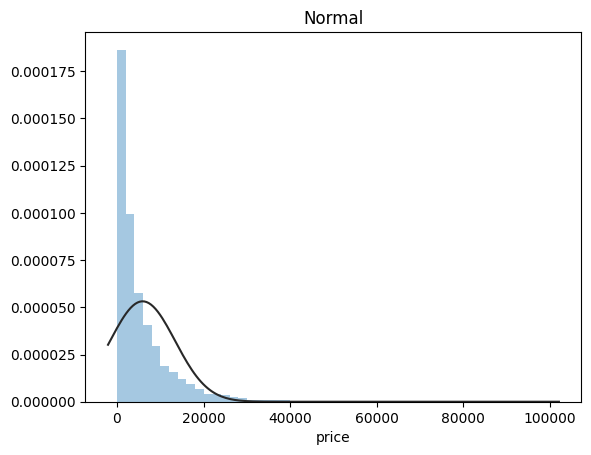

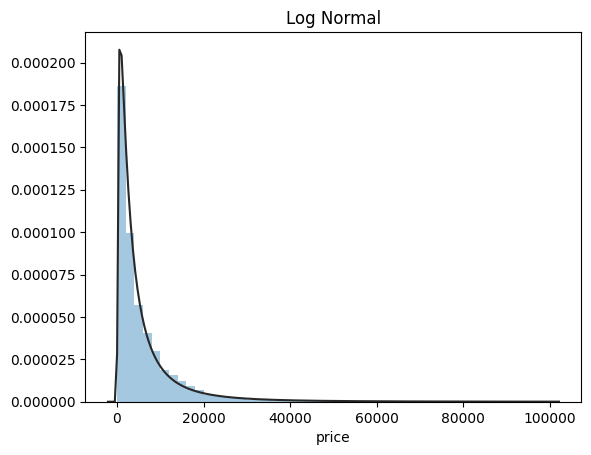

In [76]:
import scipy.stats as st# 拟合price的分布（对比Johnson SU、正态、对数正态分布）
y = train_data['price']
plt.figure(1); plt.title('Johnson SU')
sns.distplot(y, kde=False, fit=st.johnsonsu)
plt.figure(2); plt.title('Normal')
sns.distplot(y, kde=False, fit=st.norm)
plt.figure(3); plt.title('Log Normal')
sns.distplot(y, kde=False, fit=st.lognorm)

Skewness: 3.346487
Kurtosis: 18.995183


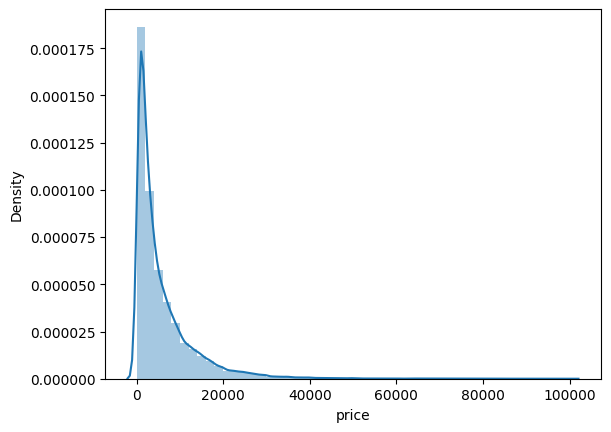

In [79]:
sns.distplot(train_data['price']);
print("Skewness: %f" % train_data['price'].skew())
print("Kurtosis: %f" % train_data['price'].kurt())# 计算price的偏度和峰度

In [81]:
 train_data.skew(), train_data.kurt()

(SaleID                0.000000
 name                  0.557606
 regDate               0.028495
 model                 1.484388
 brand                 1.150760
 bodyType              0.991530
 fuelType              1.595486
 gearbox               1.317514
 power                65.863178
 kilometer            -1.525921
 notRepairedDamage     2.430640
 regionCode            0.688881
 creatDate           -79.013310
 price                 3.346487
 v_0                  -1.316712
 v_1                   0.359454
 v_2                   4.842556
 v_3                   0.106292
 v_4                   0.367989
 v_5                  -4.737094
 v_6                   0.368073
 v_7                   5.130233
 v_8                   0.204613
 v_9                   0.419501
 v_10                  0.025220
 v_11                  3.029146
 v_12                  0.365358
 v_13                  0.267915
 v_14                 -1.186355
 dtype: float64,
 SaleID                 -1.200000
 name                

<AxesSubplot:xlabel='Skewness', ylabel='Density'>

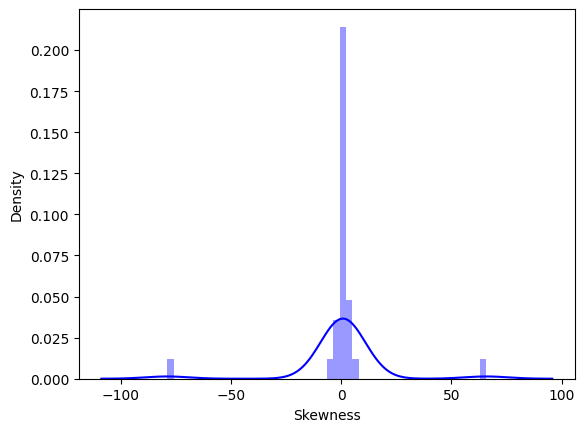

In [82]:
sns.distplot(train_data.skew(),color='blue',axlabel ='Skewness')# 输出：3.346487（右偏）

<AxesSubplot:xlabel='Kurtness', ylabel='Density'>

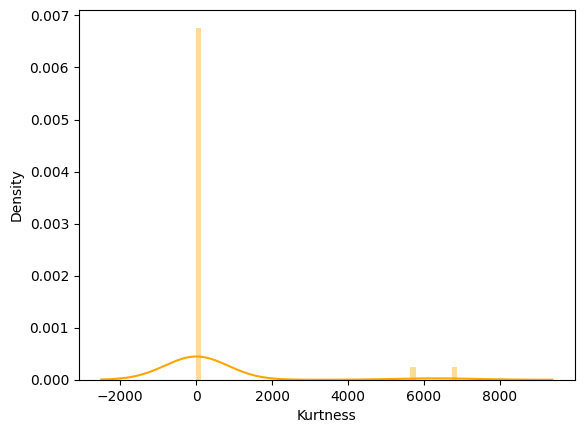

In [83]:
 sns.distplot(train_data.kurt(),color='orange',axlabel ='Kurtness')# 输出：18.995183（高峰）

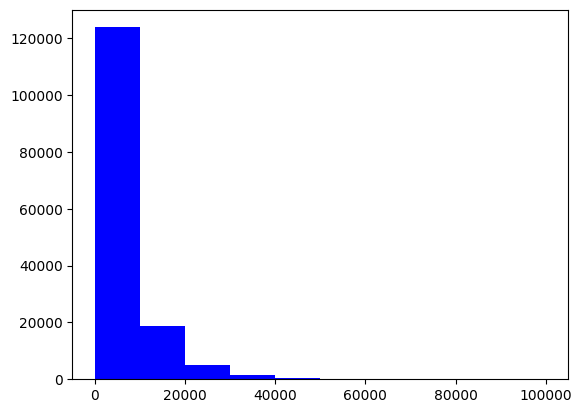

In [84]:
plt.hist(train_data['price'], orientation = 'vertical',histtype = 'bar', color ='blue')
plt.show()# 可视化price的原始分布

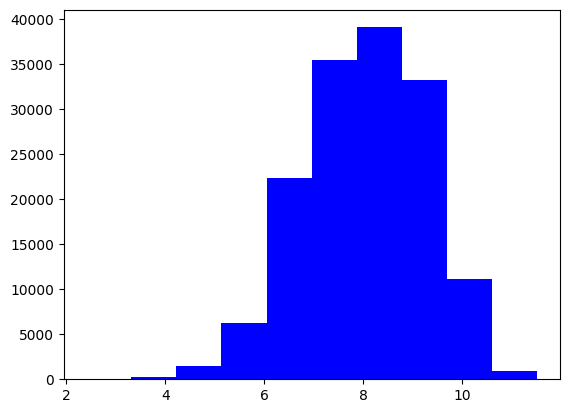

In [85]:
plt.hist(np.log(train_data['price']), orientation = 'vertical',histtype = 'bar', color ='blue') 
plt.show()# 可视化price的对数转换后分布

In [ ]:
原理说明
目标变量分布意义：price是预测目标，其分布特性影响模型选择（如线性模型假设目标变量近似正态分布）。
偏度与峰度：
偏度（Skewness）>0 表示右偏（大部分值集中在左侧，少数高值拉偏分布），price偏度 3.34 说明存在较多高价车拉高均值。
峰度（Kurtosis）>3 表示高蜂分布（数据更集中在均值附近），price峰度 18.99 说明多数车辆价格集中在较低区间。
分布转换：对数转换（np.log(price)）可改善右偏分布，使数据更接近正态，提升线性模型效果。

In [87]:
Y_train = train_data['price']

In [89]:
# 特征分类（数值型与分类型）
numeric_features = ['power', 'kilometer', 'v_0', 'v_1', 'v_2', 'v_3', 'v_4', 'v_5', 'v_6', 'v_7', 'v_8', 'v_9', 'v_10', 'v_11', 'v_12', 'v_13','v_14' ]
categorical_features = ['name', 'model', 'brand', 'bodyType', 'fuelType', 'gearbox', 'notRepairedDamage', 'regionCode',]

In [91]:
# 分类型特征分布分析
for cat_fea in categorical_features:
    print(cat_fea + "的特征分布如下：")
    print("{}特征有个{}不同的值".format(cat_fea, train_data[cat_fea].nunique()))
    print(train_data[cat_fea].value_counts())

name的特征分布如下：
name特征有个99662不同的值
387       282
708       282
55        280
1541      263
203       233
         ... 
26403       1
28450       1
32544       1
102174      1
184730      1
Name: name, Length: 99662, dtype: int64
model的特征分布如下：
model特征有个248不同的值
0.0      11762
19.0      9573
4.0       8445
1.0       6038
29.0      5186
         ...  
242.0        2
209.0        2
245.0        2
240.0        2
247.0        1
Name: model, Length: 248, dtype: int64
brand的特征分布如下：
brand特征有个40不同的值
0     31480
4     16737
14    16089
10    14249
1     13794
6     10217
9      7306
5      4665
13     3817
11     2945
3      2461
7      2361
16     2223
8      2077
25     2064
27     2053
21     1547
15     1458
19     1388
20     1236
12     1109
22     1085
26      966
30      940
17      913
24      772
28      649
32      592
29      406
37      333
2       321
31      318
18      316
36      228
34      227
33      218
23      186
35      180
38       65
39        9
Name: brand, dtype: int64
body

In [ ]:
原理说明
特征分类依据：
数值型特征：取值为连续或离散数值（如power表示功率，kilometer表示里程），可计算相关性、偏度等。
分类型特征：取值为类别（如brand表示品牌，gearbox表示变速箱类型），需分析不同类别与price的关系。
分类型特征分析意义：
如brand有 40 个取值，不同品牌的样本数量差异大（品牌 0 有 31480 样本，品牌 39 仅 9 样本），可能影响模型对小众品牌的预测。
gearbox（变速箱）分 0/1 两类，0 对应 111623 样本，1 对应 32396 样本，可后续分析手动 / 自动变速箱对价格的影响。

In [93]:
numeric_features.append('price')

In [94]:
numeric_features

['power',
 'kilometer',
 'v_0',
 'v_1',
 'v_2',
 'v_3',
 'v_4',
 'v_5',
 'v_6',
 'v_7',
 'v_8',
 'v_9',
 'v_10',
 'v_11',
 'v_12',
 'v_13',
 'v_14',
 'price']

In [96]:
# 计算数值特征与price的相关性
price_numeric = train_data[numeric_features]# 筛选数值特征+price
correlation = price_numeric.corr()# 计算皮尔逊相关系数
print(correlation['price'].sort_values(ascending = False),'\n')# 按与price的相关性排序


price        1.000000
v_12         0.692823
v_8          0.685798
v_0          0.628397
power        0.219834
v_5          0.164317
v_2          0.085322
v_6          0.068970
v_1          0.060914
v_14         0.035911
v_13        -0.013993
v_7         -0.053024
v_4         -0.147085
v_9         -0.206205
v_10        -0.246175
v_11        -0.275320
kilometer   -0.440519
v_3         -0.730946
Name: price, dtype: float64 



In [98]:
del price_numeric['price']

In [2]:
price_numeric = train_data[numeric_features + ['price']]  # 筛选数值特征+price
correlation = price_numeric.corr()  # 计算皮尔逊相关系数
print(correlation['price'].sort_values(ascending=False))  # 按与price的相关性排序

NameError: name 'train_data' is not defined

In [ ]:
f, ax = plt.subplots(figsize=(7, 7))
plt.title("Correlation of Numeric Features with Price", y=1, size=16)
sns.heatmap(correlation, square=True, vmax=0.8)  # 热力图展示相关性

原理说明
相关性意义：皮尔逊相关系数衡量变量间线性相关程度（范围 [-1,1]），正值表示正相关（如v_12越大，price越高），负值表示负相关（如v_3越大，price越低），绝对值越大相关性越强。
特征重要性初步判断：v_12、v_8与price强正相关，v_3强负相关，这些特征可能对价格预测起关键作用，后续建模可重点关注。

In [100]:
for col in numeric_features:
    print('{:15}'.format(col),
          'Skewness: {:05.2f}'.format(train_data[col].skew()) ,
          '   ' , 
          'Kurtosis: {:06.2f}'.format(train_data[col].kurt()) 
         )

power           Skewness: 65.86     Kurtosis: 5733.45
kilometer       Skewness: -1.53     Kurtosis: 001.14
v_0             Skewness: -1.32     Kurtosis: 003.99
v_1             Skewness: 00.36     Kurtosis: -01.75
v_2             Skewness: 04.84     Kurtosis: 023.86
v_3             Skewness: 00.11     Kurtosis: -00.42
v_4             Skewness: 00.37     Kurtosis: -00.20
v_5             Skewness: -4.74     Kurtosis: 022.93
v_6             Skewness: 00.37     Kurtosis: -01.74
v_7             Skewness: 05.13     Kurtosis: 025.85
v_8             Skewness: 00.20     Kurtosis: -00.64
v_9             Skewness: 00.42     Kurtosis: -00.32
v_10            Skewness: 00.03     Kurtosis: -00.58
v_11            Skewness: 03.03     Kurtosis: 012.57
v_12            Skewness: 00.37     Kurtosis: 000.27
v_13            Skewness: 00.27     Kurtosis: -00.44
v_14            Skewness: -1.19     Kurtosis: 002.39
price           Skewness: 03.35     Kurtosis: 019.00


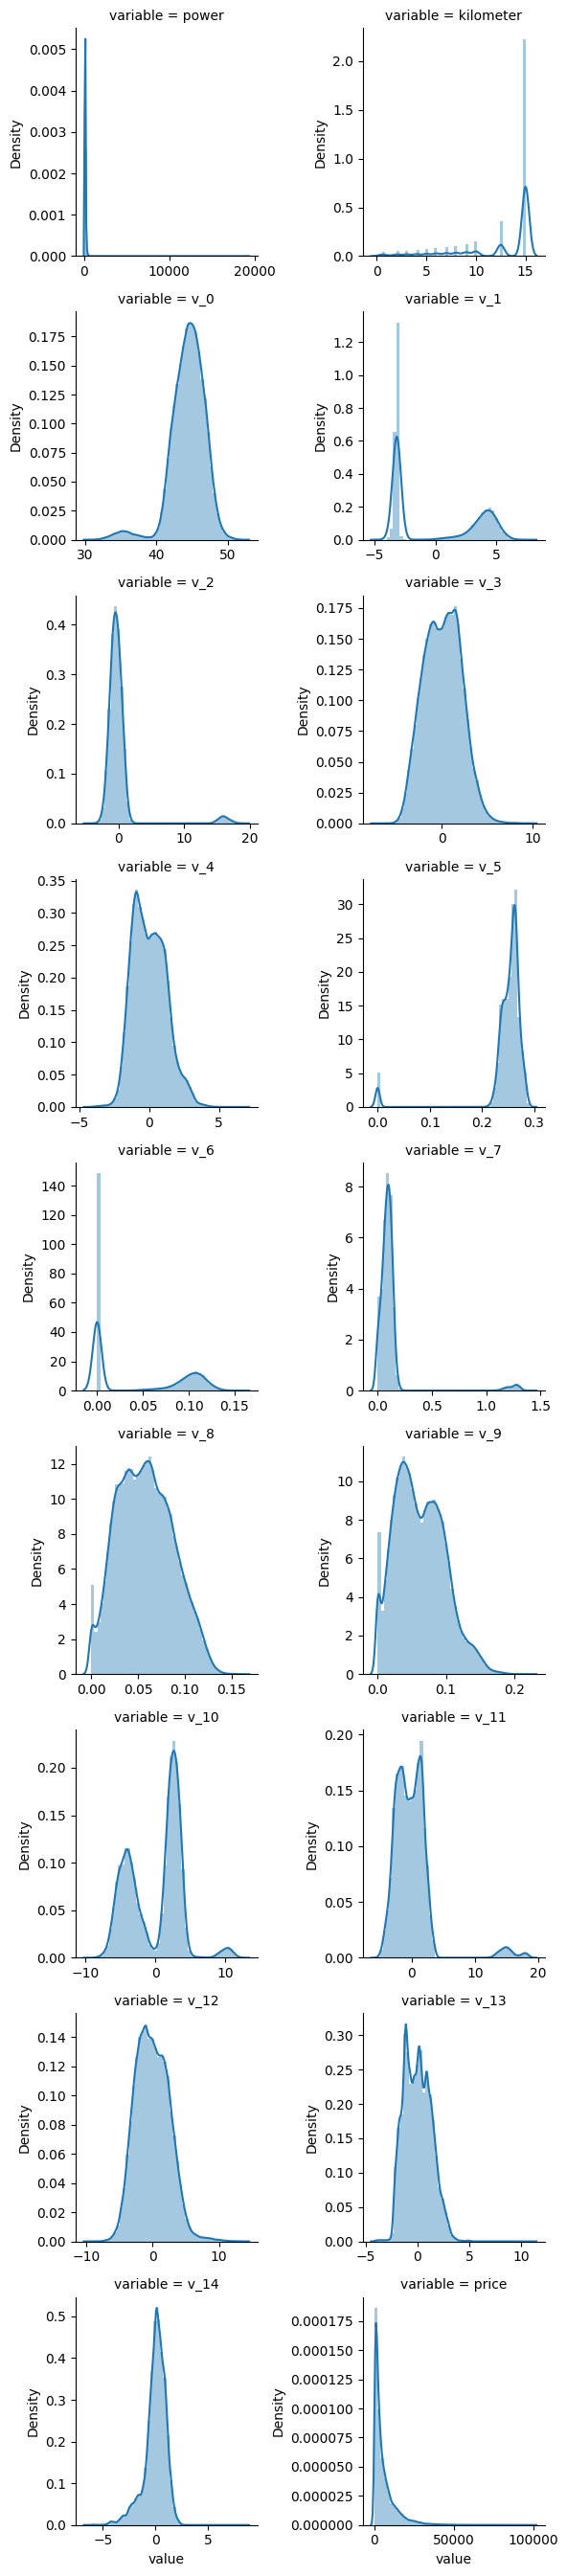

In [101]:
f = pd.melt(train_data, value_vars=numeric_features)
g = sns.FacetGrid(f, col="variable",  col_wrap=2, sharex=False, sharey=False)
g = g.map(sns.distplot, "value")

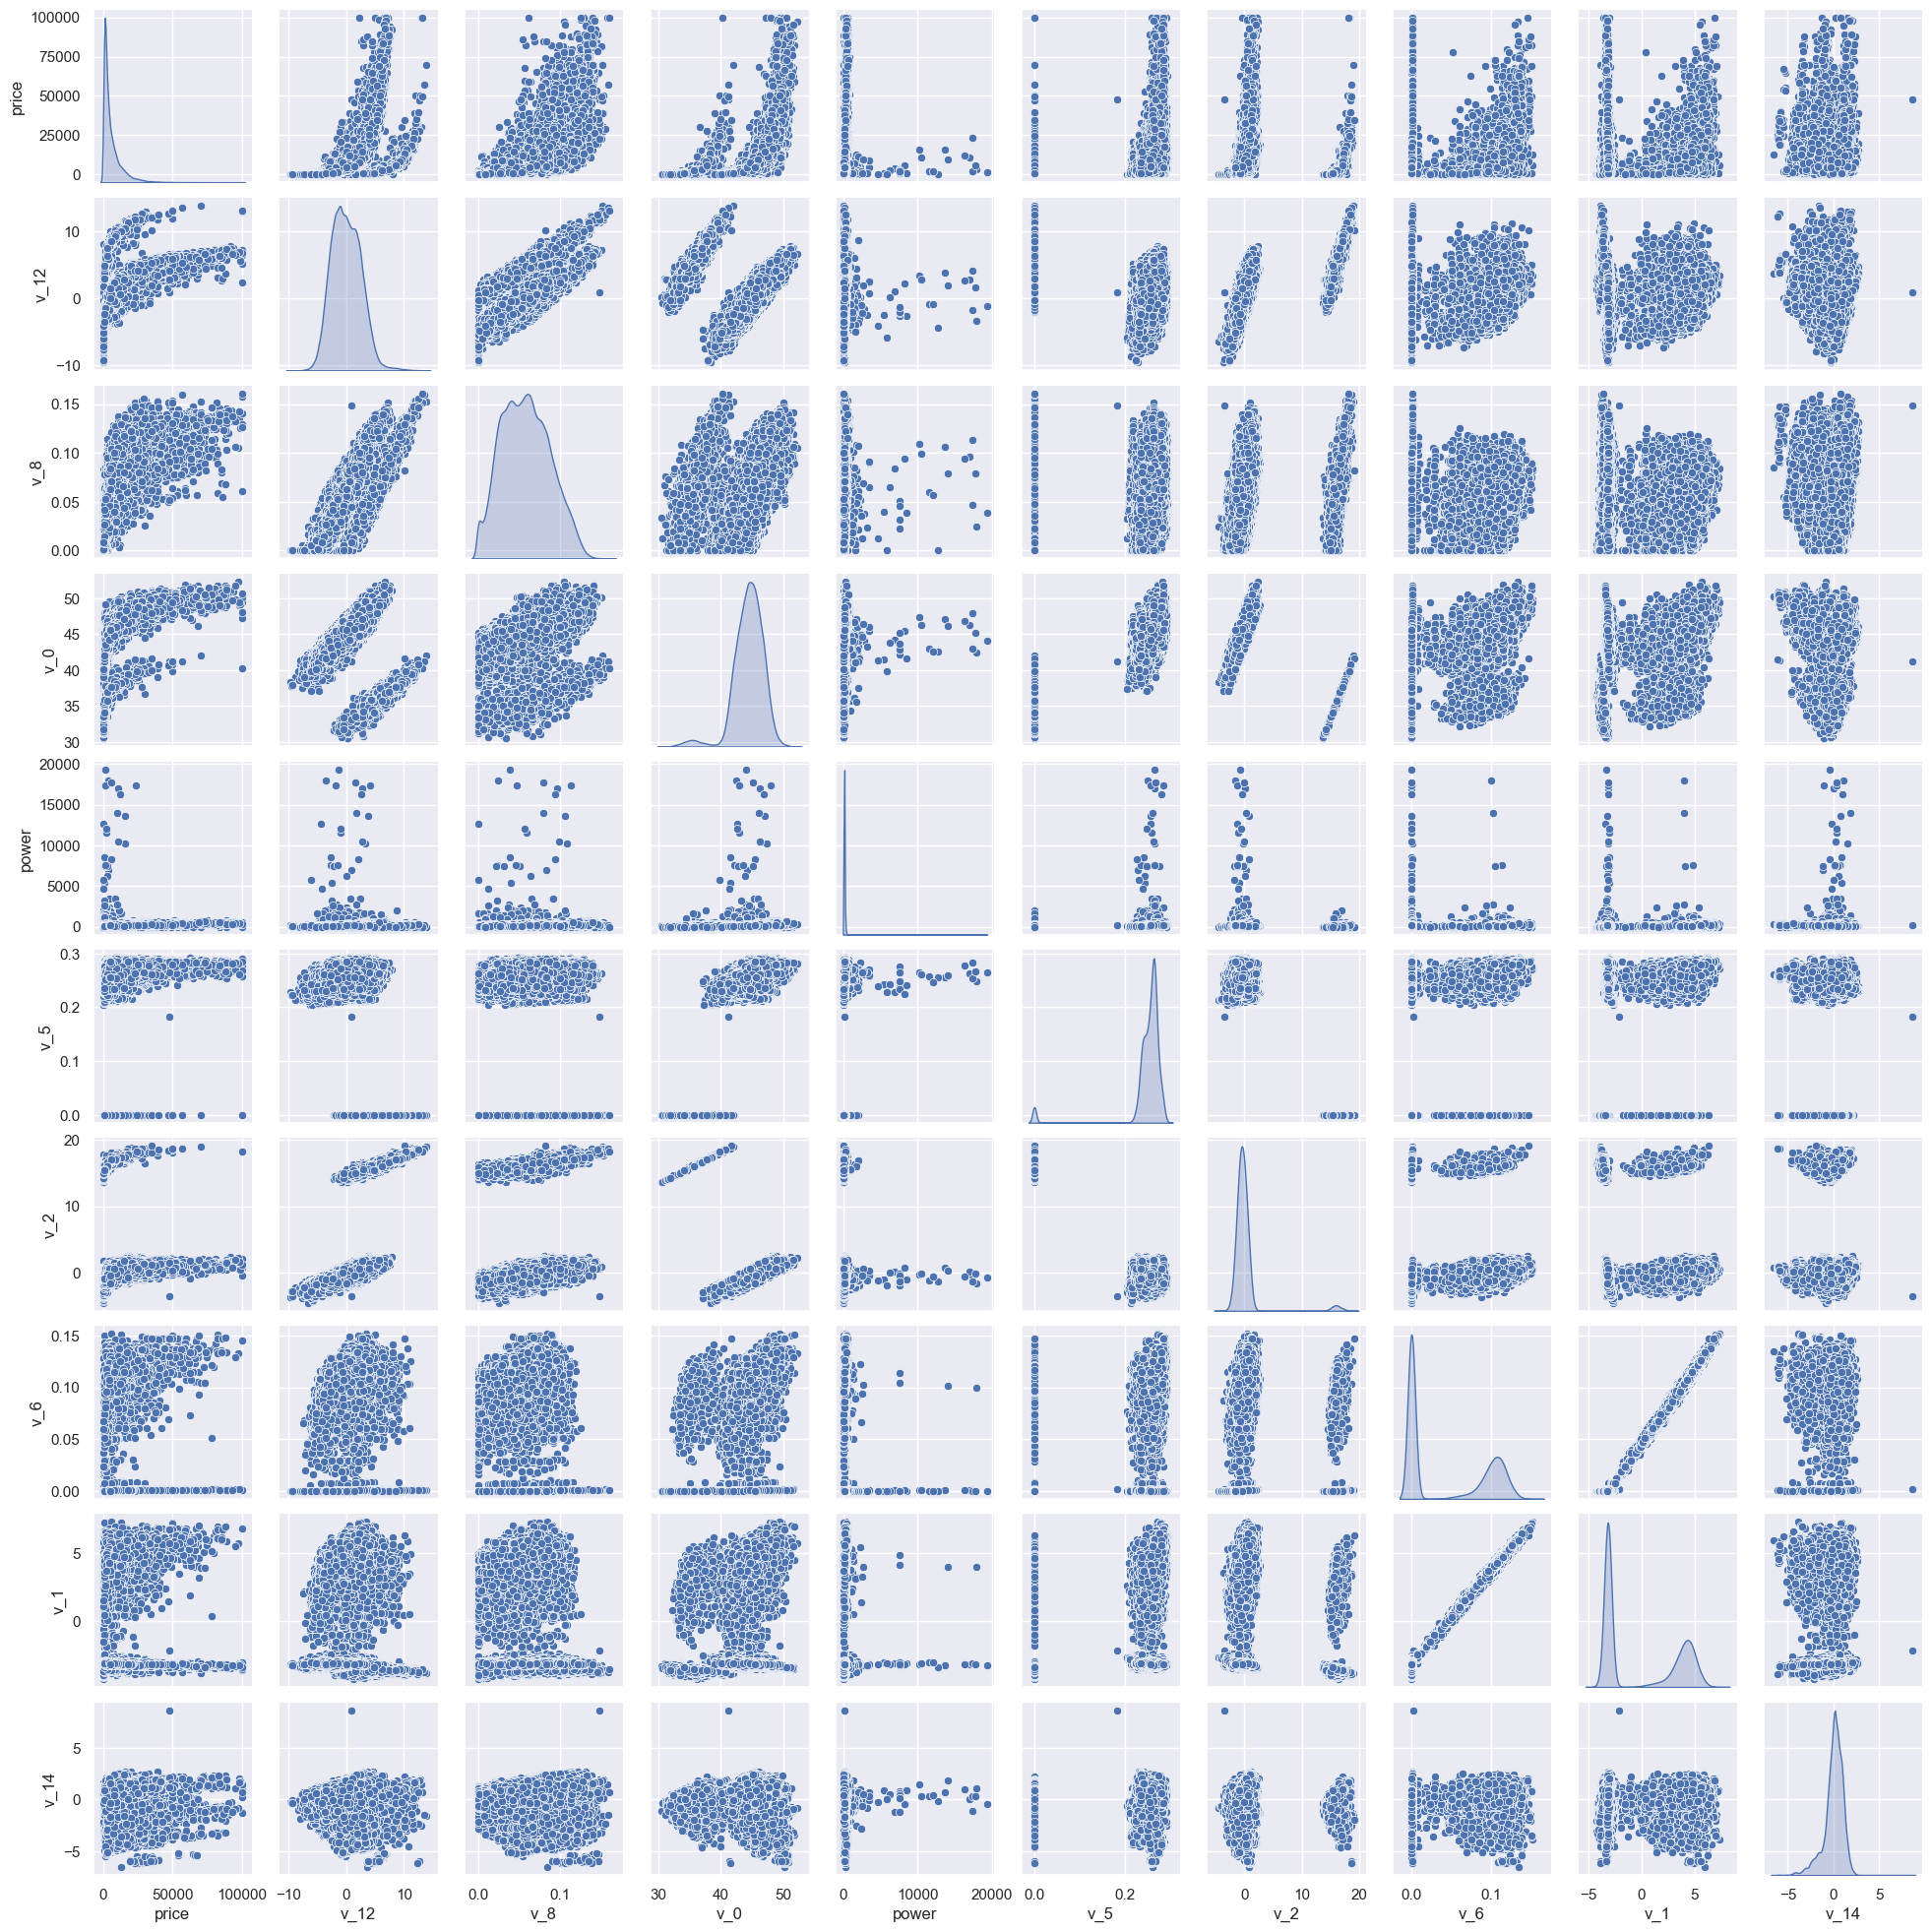

In [102]:
sns.set()
columns = ['price', 'v_12', 'v_8' , 'v_0', 'power', 'v_5',  'v_2', 'v_6', 'v_1', 'v_14']
sns.pairplot(train_data[columns],size = 2 ,kind ='scatter',diag_kind='kde')
plt.show()

In [103]:
train_data.columns

Index(['SaleID', 'name', 'regDate', 'model', 'brand', 'bodyType', 'fuelType',
       'gearbox', 'power', 'kilometer', 'notRepairedDamage', 'regionCode',
       'creatDate', 'price', 'v_0', 'v_1', 'v_2', 'v_3', 'v_4', 'v_5', 'v_6',
       'v_7', 'v_8', 'v_9', 'v_10', 'v_11', 'v_12', 'v_13', 'v_14'],
      dtype='object')

In [104]:
 Y_train

0         1850
1         3600
2         6222
3         2400
4         5200
          ... 
149995    5900
149996    9500
149997    7500
149998    4999
149999    4700
Name: price, Length: 150000, dtype: int64

<AxesSubplot:xlabel='v_13', ylabel='price'>

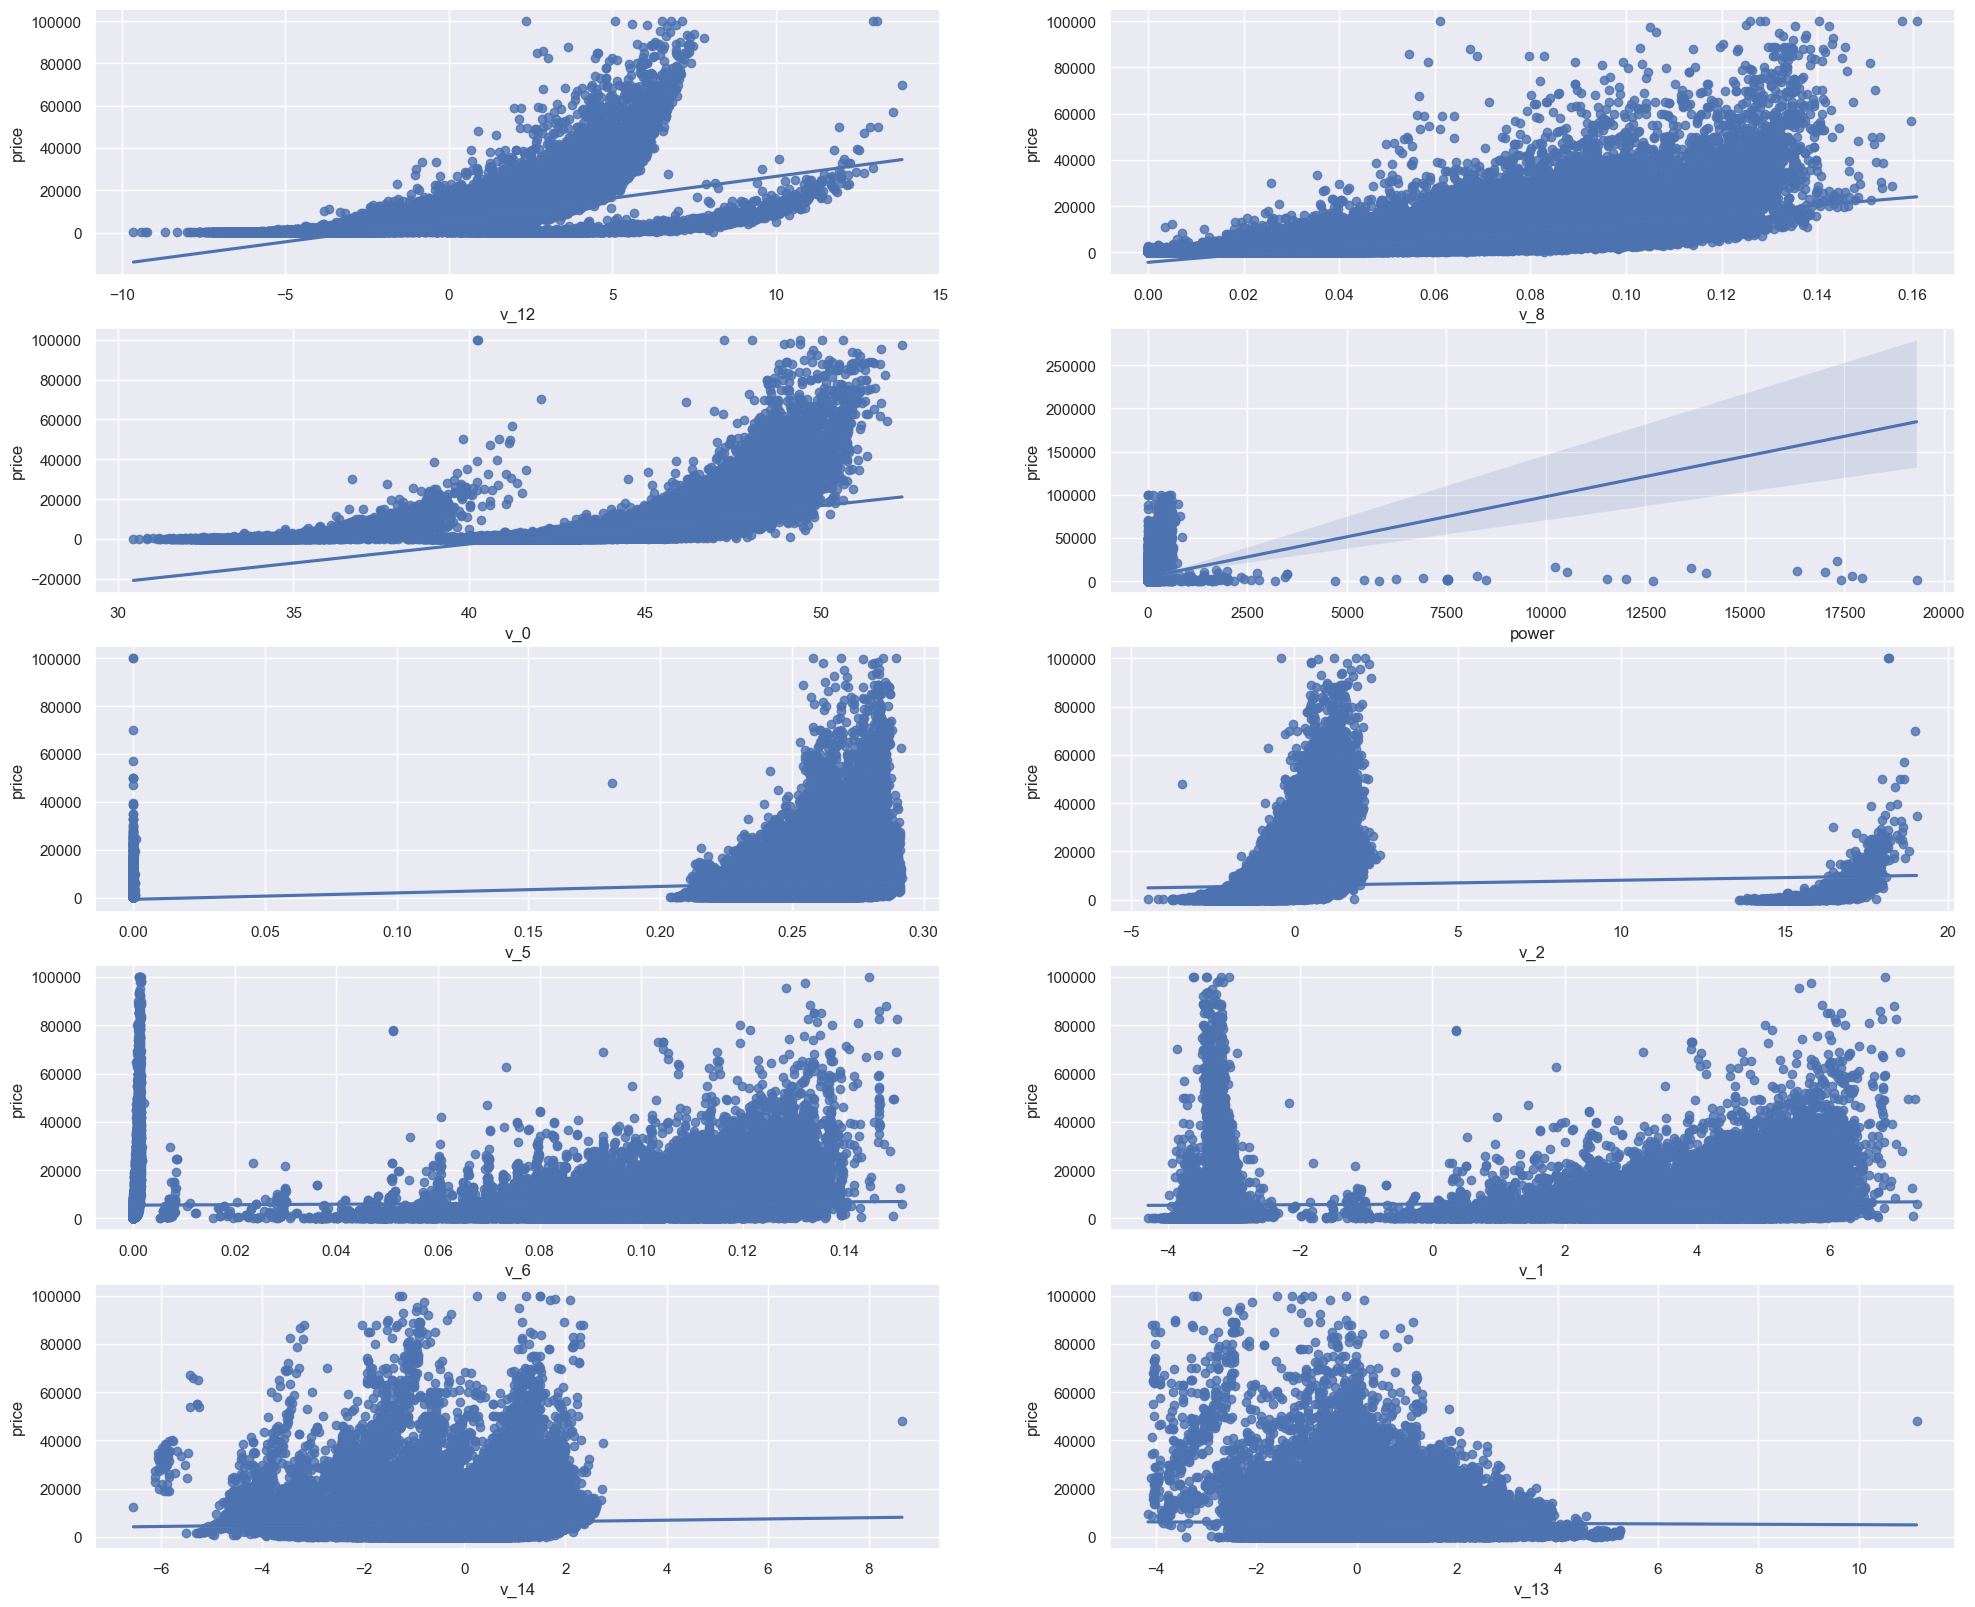

In [106]:
## 5) 多变量互相回归关系可视化
fig, ((ax1, ax2), (ax3, ax4), (ax5, ax6), (ax7, ax8), (ax9, ax10)) = plt.subplots(nrows=5, ncols=2, figsize=(24, 20))
 # ['v_12', 'v_8' , 'v_0', 'power', 'v_5',  'v_2', 'v_6', 'v_1', 'v_14']
v_12_scatter_plot = pd.concat([Y_train,train_data['v_12']],axis = 1)
sns.regplot(x='v_12',y = 'price', data = v_12_scatter_plot,scatter= True, fit_reg=True, ax=ax1)
v_8_scatter_plot = pd.concat([Y_train,train_data['v_8']],axis = 1)
sns.regplot(x='v_8',y = 'price',data = v_8_scatter_plot,scatter= True, fit_reg=True, ax=ax2)
v_0_scatter_plot = pd.concat([Y_train,train_data['v_0']],axis = 1)
sns.regplot(x='v_0',y = 'price',data = v_0_scatter_plot,scatter= True, fit_reg=True, ax=ax3)
power_scatter_plot = pd.concat([Y_train,train_data['power']],axis = 1)
sns.regplot(x='power',y = 'price',data = power_scatter_plot,scatter= True, fit_reg=True, ax=ax4)
v_5_scatter_plot = pd.concat([Y_train,train_data['v_5']],axis = 1)
sns.regplot(x='v_5',y = 'price',data = v_5_scatter_plot,scatter= True, fit_reg=True, ax=ax5)
v_2_scatter_plot = pd.concat([Y_train,train_data['v_2']],axis = 1)
sns.regplot(x='v_2',y = 'price',data = v_2_scatter_plot,scatter= True, fit_reg=True, ax=ax6)
v_6_scatter_plot = pd.concat([Y_train,train_data['v_6']],axis = 1)
sns.regplot(x='v_6',y = 'price',data = v_6_scatter_plot,scatter= True, fit_reg=True, ax=ax7)
v_1_scatter_plot = pd.concat([Y_train,train_data['v_1']],axis = 1)
sns.regplot(x='v_1',y = 'price',data = v_1_scatter_plot,scatter= True, fit_reg=True, ax=ax8)
v_14_scatter_plot = pd.concat([Y_train,train_data['v_14']],axis = 1)
sns.regplot(x='v_14',y = 'price',data = v_14_scatter_plot,scatter= True, fit_reg=True, ax=ax9)
v_13_scatter_plot = pd.concat([Y_train,train_data['v_13']],axis = 1)
sns.regplot(x='v_13',y = 'price',data = v_13_scatter_plot,scatter= True, fit_reg=True, ax=ax10)

In [108]:
for fea in categorical_features:
    print(train_data[fea].nunique())

99662
248
40
8
7
2
2
7905


In [109]:
 categorical_features

['name',
 'model',
 'brand',
 'bodyType',
 'fuelType',
 'gearbox',
 'notRepairedDamage',
 'regionCode']

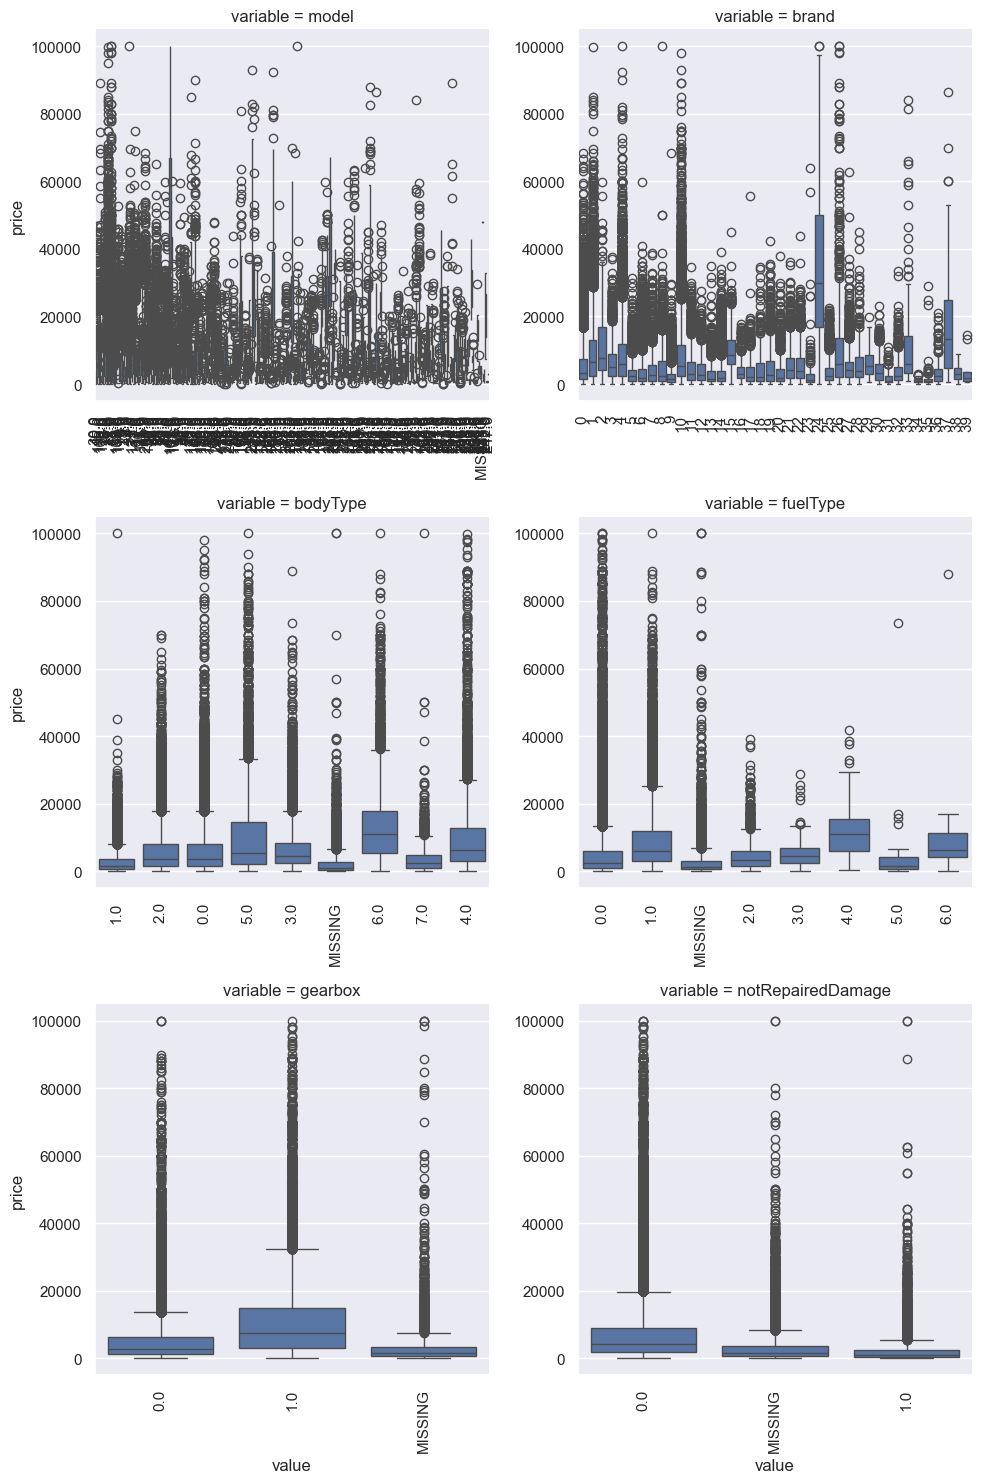

In [114]:
categorical_features = ['model',
 'brand',
 'bodyType',
 'fuelType',
 'gearbox',
 'notRepairedDamage']
for c in categorical_features:
    train_data[c] = train_data[c].astype('category')
    if train_data[c].isnull().any():
        train_data[c] = train_data[c].cat.add_categories(['MISSING'])
        train_data[c] = train_data[c].fillna('MISSING')
        
def boxplot(x, y, **kwargs):
    sns.boxplot(x=x, y=y)
    x=plt.xticks(rotation=90)
    
f = pd.melt(train_data, id_vars=['price'], value_vars=categorical_features)
g = sns.FacetGrid(f, col="variable",  col_wrap=2, sharex=False, sharey=False, height=5)
g = g.map(boxplot, "value", "price")

In [115]:
train_data.columns

Index(['SaleID', 'name', 'regDate', 'model', 'brand', 'bodyType', 'fuelType',
       'gearbox', 'power', 'kilometer', 'notRepairedDamage', 'regionCode',
       'creatDate', 'price', 'v_0', 'v_1', 'v_2', 'v_3', 'v_4', 'v_5', 'v_6',
       'v_7', 'v_8', 'v_9', 'v_10', 'v_11', 'v_12', 'v_13', 'v_14'],
      dtype='object')

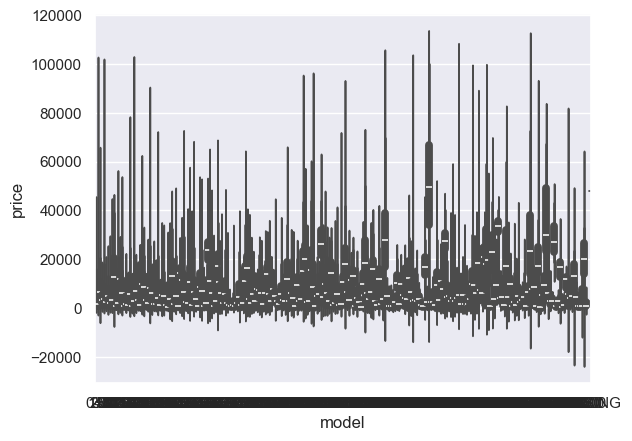

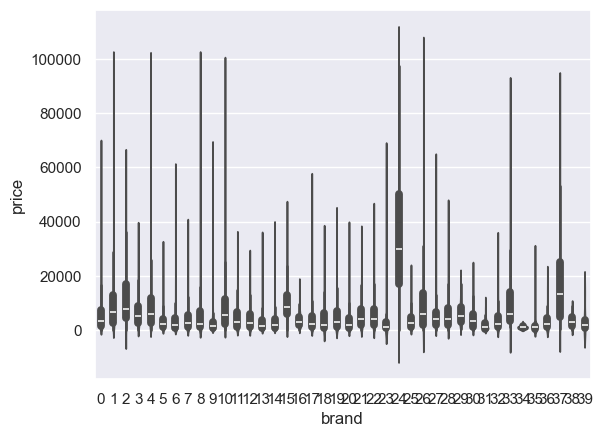

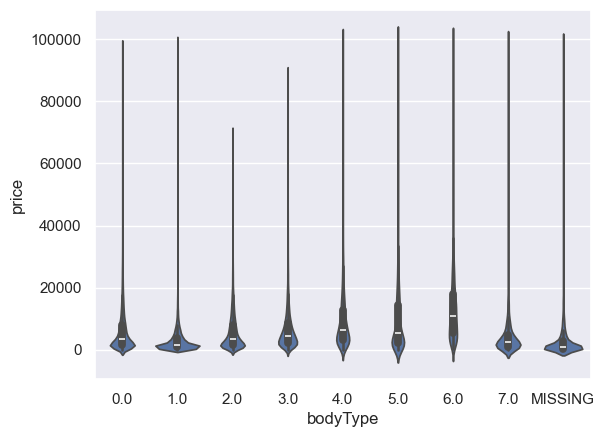

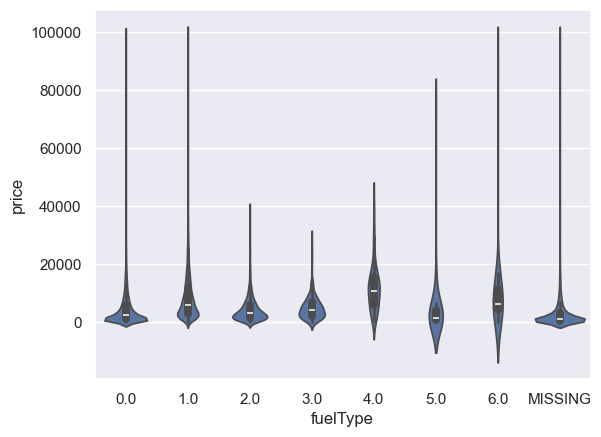

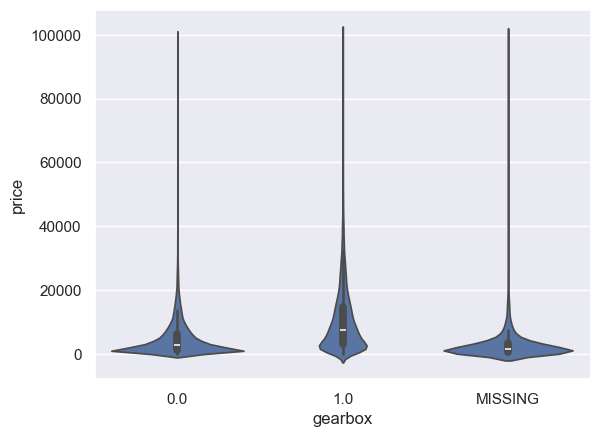

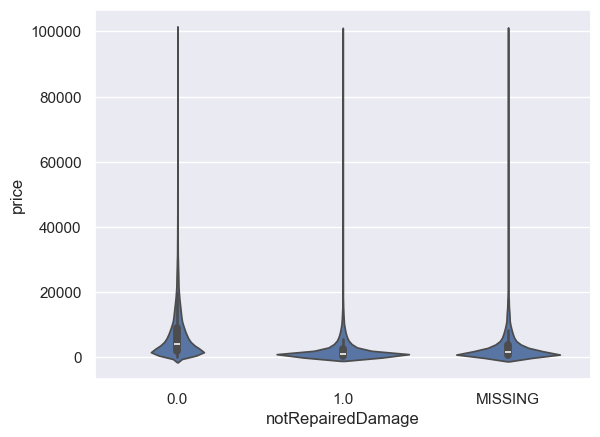

In [117]:
catg_list = categorical_features
target = 'price'
for catg in catg_list :
    sns.violinplot(x=catg, y=target, data=train_data)
    plt.show()

In [118]:
categorical_features = ['model',
 'brand',
 'bodyType',
 'fuelType',
 'gearbox',
 'notRepairedDamage']

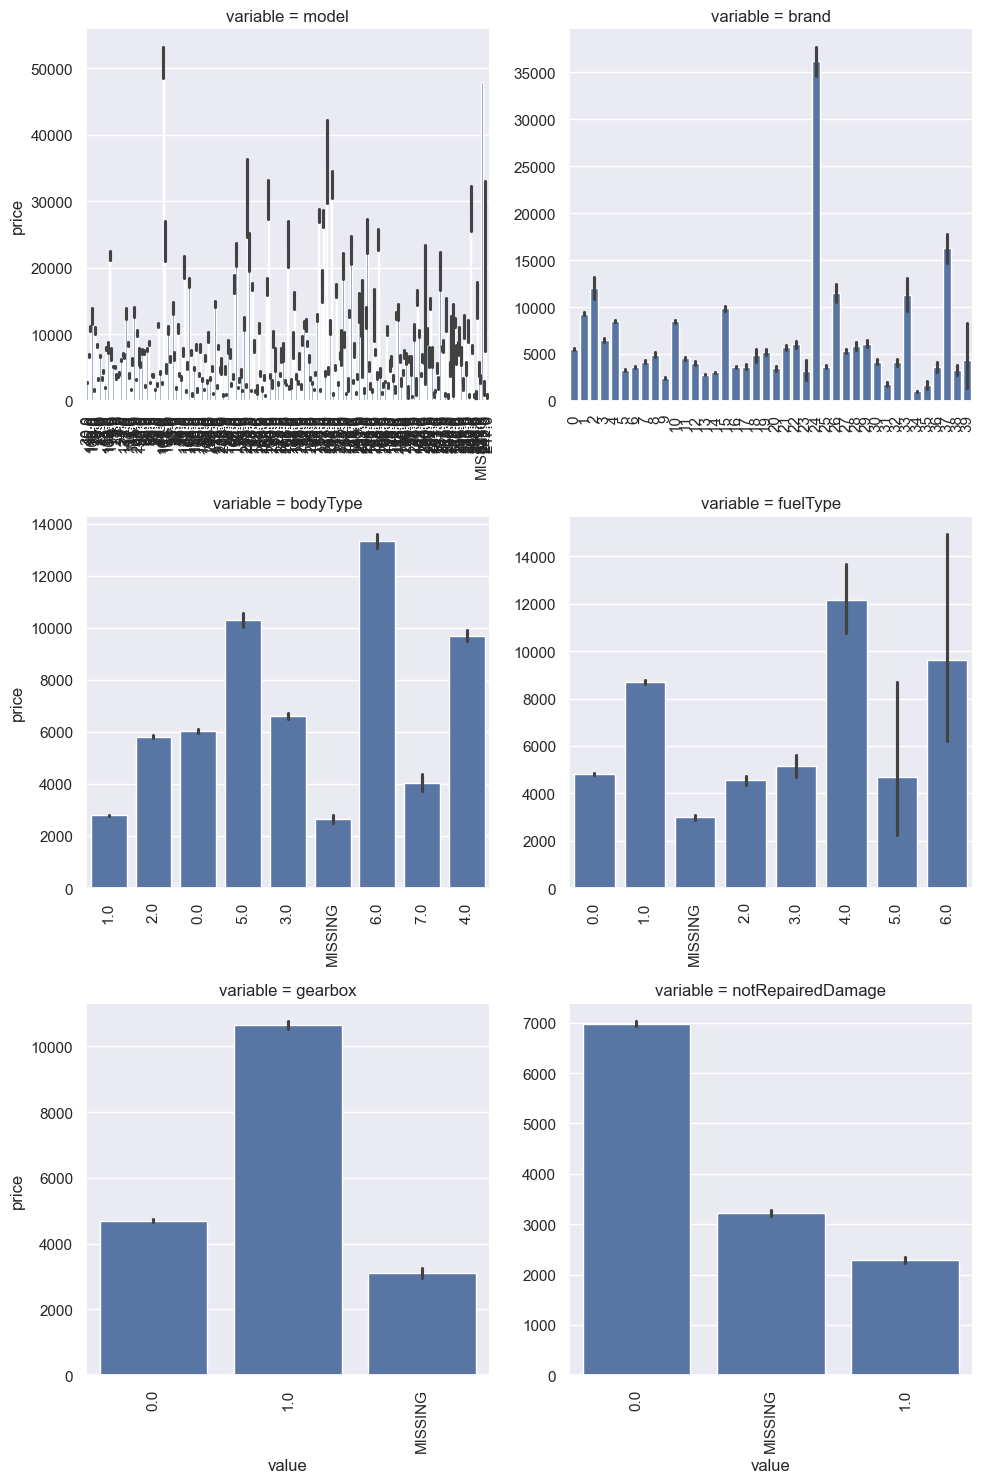

In [119]:
def bar_plot(x, y, **kwargs):
    sns.barplot(x=x, y=y)
    x=plt.xticks(rotation=90)
    
f = pd.melt(train_data, id_vars=['price'], value_vars=categorical_features)
g = sns.FacetGrid(f, col="variable",  col_wrap=2, sharex=False, sharey=False, height=5)
g = g.map(bar_plot, "value", "price")

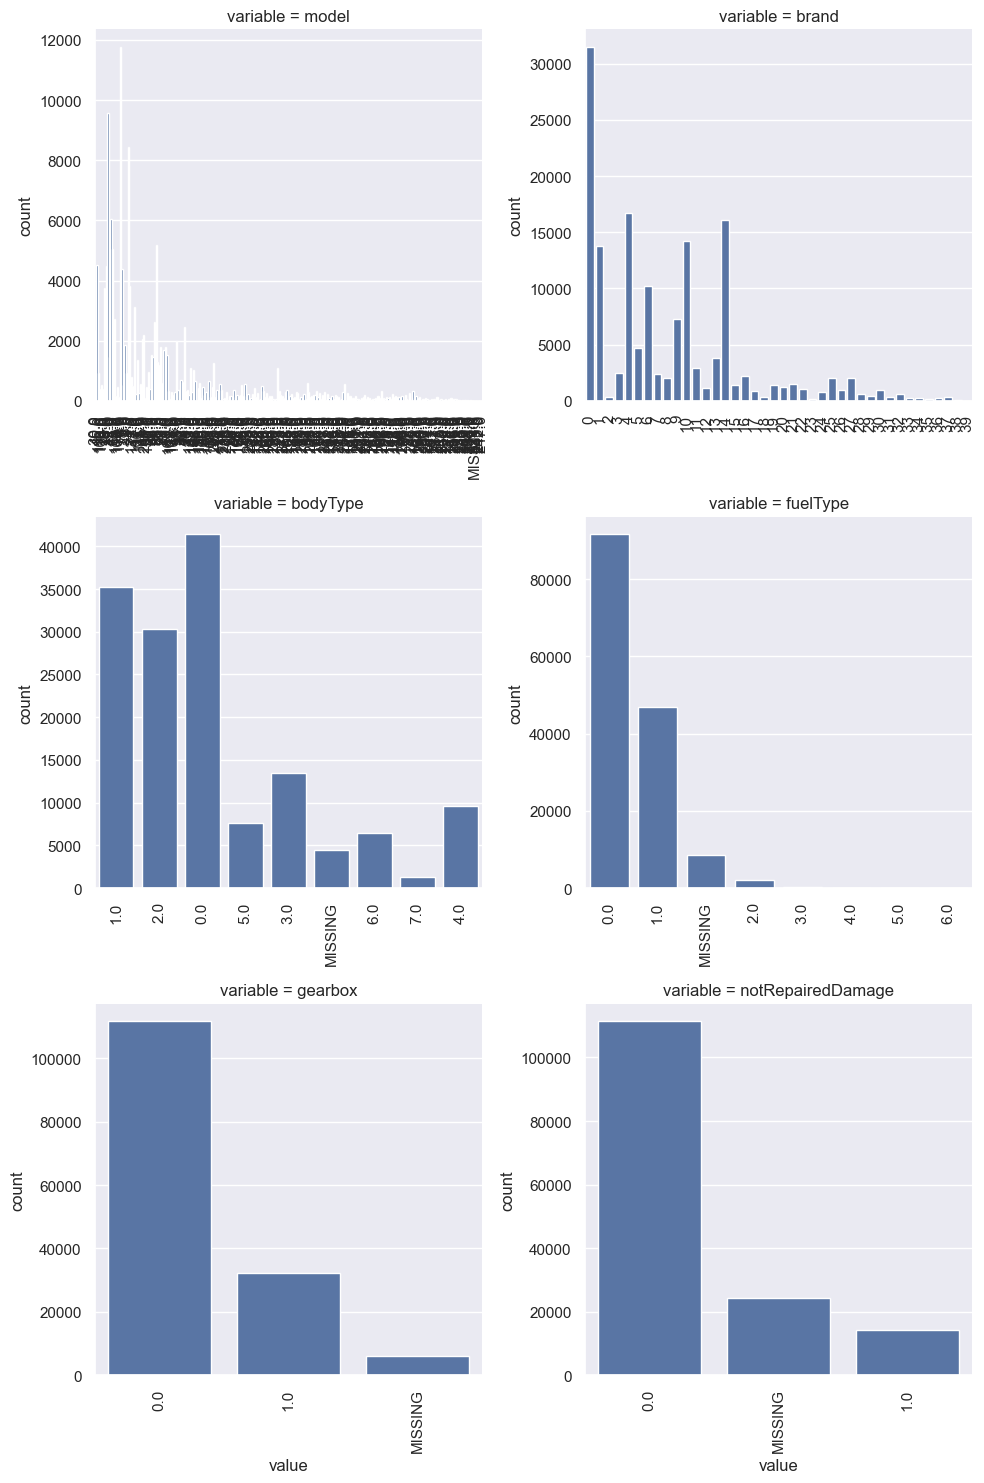

In [120]:
def count_plot(x,  **kwargs):
    sns.countplot(x=x)
    x=plt.xticks(rotation=90)
f = pd.melt(train_data,  value_vars=categorical_features)
g = sns.FacetGrid(f, col="variable",  col_wrap=2, sharex=False, sharey=False, height=5)
g = g.map(count_plot, "value")

In [142]:
# 创建新环境
import subprocess
import sys

# 创建新虚拟环境
venv_name = "pandas_profiling_env"
subprocess.run([sys.executable, "-m", "venv", venv_name])

# 激活环境并安装兼容版本
if sys.platform.startswith("win"):
    activate_script = f"{venv_name}\\Scripts\\activate"
    pip_path = f"{venv_name}\\Scripts\\pip"
else:
    activate_script = f"source {venv_name}/bin/activate"
    pip_path = f"{venv_name}/bin/pip"

# 安装兼容版本
commands = [
    f"{pip_path} install pandas-profiling==3.6.6",
    f"{pip_path} install htmlmin==0.1.12",
    f"{pip_path} install pydantic==1.10.14",
    f"{pip_path} install pandas"
]

for cmd in commands:
    subprocess.run(cmd, shell=True)

# 在新环境中运行代码
script = f"""
import pandas as pd
import pandas_profiling

# 加载数据
Train_data = pd.read_csv(r'G:\\第三周\\used_car_train_20200313.csv', sep=' ')

# 创建报告
pfr = pandas_profiling.ProfileReport(
    Train_data,
    title="二手车数据分析报告",
    correlations={{
        "auto": {{"calculate": True}},
        "pearson": {{"calculate": True}},
        "spearman": {{"calculate": True}},
        "kendall": {{"calculate": True}},
        "phi_k": {{"calculate": True}},
    }}
)

# 保存报告
pfr.to_file("./example.html")

print("报告已成功保存为 example.html")
"""

# 保存脚本
with open("generate_report.py", "w", encoding="utf-8") as f:
    f.write(script)

# 在新环境中执行脚本
if sys.platform.startswith("win"):
    python_path = f"{venv_name}\\Scripts\\python"
else:
    python_path = f"{venv_name}/bin/python"

subprocess.run([python_path, "generate_report.py"])

print("\n报告生成完成！请查看 example.html 文件")


报告生成完成！请查看 example.html 文件
